# Spectrogram dataset generator for RF signal detection and modulation-family classification

Implements the dataset specification in `R&D.md` (Sections 2, 3 and 8). Everything is **synthetic and labeled automatically**: the generator knows the exact parameters of every signal it creates.

| Item | Value |
|---|---|
| Band / receiver model | VHF/UHF, USRP-like (12/14-bit ADC, TCXO offset, IQ imbalance, DC spike, band-edge roll-off) |
| Sample rate | 256 kS/s complex |
| Spectrogram | N_fft = 1024 (250 Hz bins, 4 ms window), hop 256 (1 ms), 128 frames (about 131 ms) |
| SNR | 5 to 30 dB in-band (out-of-range stress set kept separate). `train` is skewed towards low SNR (truncated exponential, `snr_tau_train`); `val` and all test sets are uniform |
| Classes | 11 signal classes (CW, AM, NBFM, BPSK, QPSK, 8PSK, 16QAM, 64QAM, 2-FSK, 4-FSK, GMSK) + noise |
| Primary target | modulation family: CW, AM, FM, PSK, QAM, FSK/CPM (fine class and coarse group are also stored) |
| 1 kHz separation | dedicated pair set with exact center-frequency spacings, tiers, SNR and time-overlap sweeps |

**Sets written:** `train`, `val`, `test` (split by session group, no leakage) and the frozen evaluation sets `test_1khz`, `test_robust` (unseen impairments), `test_openset` (held-out classes OQPSK, 8-FSK, CHIRP), `test_snr_stress` (outside 5 to 30 dB).

**How to use:** run all cells top to bottom. Choose the size with the environment variable `SPECTRUM_PROFILE` (`smoke` about 1 minute, `pilot` about 15k scenes, `main` about 240k scenes). Array layout is `[time frame, frequency bin]`, so a spectrogram is a 128 x 1024 image, directly usable as COCO / YOLO input.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")          # one BLAS/FFT thread per worker process
import json, math, time, hashlib, platform, datetime, warnings
import multiprocessing as mp
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache

import numpy as np
import pandas as pd
import scipy
from scipy.signal import fftconvolve, get_window
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

try:
    from tqdm.auto import tqdm
except ImportError:                          # progress bars are optional
    def tqdm(x, **kw):
        return x

warnings.filterwarnings("ignore", category=DeprecationWarning, message=".*fork.*")
print("numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__, "| python", platform.python_version())

numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0 | python 3.12.11


/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

All parameters that define the dataset live here and are written to `config.json` next to the data, so every set is traceable to a generator version and seed.

In [2]:
PROFILE = os.environ.get("SPECTRUM_PROFILE", "pilot")        # "smoke" | "pilot" | "main"
STORE_IQ = os.environ.get("SPECTRUM_STORE_IQ", "1") == "1"   # raw IQ is stored next to each spectrogram (R&D 3.4)
N_WORKERS = int(os.environ.get("SPECTRUM_WORKERS", max(1, (os.cpu_count() or 2) - 1)))
REBUILD = set(filter(None, os.environ.get("SPECTRUM_REBUILD", "").split(",")))   # set names to regenerate
FORCE_FROZEN = os.environ.get("SPECTRUM_FORCE_FROZEN", "0") == "1"                # needed to regenerate a frozen test set

SET_SIZES_BY_PROFILE = {
    "smoke": dict(train=160,    val=40,    test=40,    test_1khz=60,    test_robust=40,    test_openset=40,    test_snr_stress=40),
    "pilot": dict(train=7000,   val=1500,  test=1500,  test_1khz=2000,  test_robust=1000,  test_openset=1000,  test_snr_stress=1000),
    "main":  dict(train=140000, val=30000, test=30000, test_1khz=20000, test_robust=10000, test_openset=10000, test_snr_stress=10000),
}
SET_SIZES = SET_SIZES_BY_PROFILE[PROFILE]
SET_IDS = {name: i for i, name in enumerate(SET_SIZES)}      # stable ids used for seeding
FROZEN_SETS = {"test", "test_1khz", "test_robust", "test_openset", "test_snr_stress"}
SET_MODE = {"test_1khz": "pair", "test_openset": "openset", "test_snr_stress": "snr_stress"}   # default: "general"


@dataclass(frozen=True)
class Cfg:
    version: str = "0.2.0"
    base_seed: int = 20261029
    
    fs: float = 256_000.0
    n_fft: int = 1024
    hop: int = 256
    n_frames: int = 128
    # --- SNR (R&D 2.5): in-band SNR over the occupied bandwidth, reference bandwidth floored at ref_bw_min_hz
    snr_range: tuple = (5.0, 30.0)
    snr_tau_train: float = 8.0       # dB; train SNR ~ truncated exponential from 5 dB (about 75% of signals below 15 dB). None = uniform. val/test stay uniform
    snr_stress_ranges: tuple = ((-5.0, 5.0), (30.0, 35.0))
    ref_bw_min_hz: float = 500.0
    obw_fraction: float = 0.99
    # --- storage
    db_min: float = -20.0            # spectrogram stored as uint8 dB relative to the noise floor
    db_max: float = 60.0
    group_size: int = 50             # scenes per "capture session" (shared receiver state); splits never cut a group
    shard_size: int = 250
    # --- scene composition (R&D 3.2)
    n_signals_probs: tuple = (0.10, 0.30, 0.30, 0.20, 0.10)       # 0..4 signals per scene
    burst_types: tuple = ("continuous", "long", "short", "very_short", "train")
    burst_probs: tuple = (0.35, 0.25, 0.20, 0.10, 0.10)
    min_symbols: int = 8             # raise the symbol rate (up to the class maximum) so a burst holds >= 8 symbols
    guard_hz: float = 10_000.0       # keep signals this far from the band edge (covers CFO and the filter roll-off)
    hard_negative_prob: float = 0.15
    adc_headroom_db: float = 12.0

    @property
    def n_samples(self):
        return (self.n_frames - 1) * self.hop + self.n_fft

    @property
    def df(self):
        return self.fs / self.n_fft


CFG = Cfg()
FS, NS, DF = CFG.fs, CFG.n_samples, CFG.df
OUT_DIR = Path(os.environ.get("SPECTRUM_OUT", "dataset")) / f"spectrum_rf_v{CFG.version}_{PROFILE}"
print(f"profile={PROFILE}  scenes={sum(SET_SIZES.values()):,}  workers={N_WORKERS}  store_iq={STORE_IQ}")
print(f"samples/scene={NS}  duration={NS / FS * 1e3:.1f} ms  bin width={DF:.0f} Hz  window={CFG.n_fft / FS * 1e3:.1f} ms  out={OUT_DIR}")

profile=pilot  scenes=15,000  workers=14  store_iq=True
samples/scene=33536  duration=131.0 ms  bin width=250 Hz  window=4.0 ms  out=dataset_boost/spectrum_rf_v0.2.0_pilot


## 2. Class registry and label hierarchy

Each signal has three labels: the **fine class** (12 incl. noise), the **modulation family** (the primary classification target), and a **coarse group** (PSK and QAM merged as "LinearDigital", the level a magnitude spectrogram can realistically separate). The three held-out classes appear **only** in `test_openset`.

In [3]:
CLASS_TABLE = [   # id, name, family, coarse group
    (0, "CW", "CW", "Carrier"),
    (1, "AM", "AM", "Analog"),
    (2, "NBFM", "FM", "Analog"),
    (3, "BPSK", "PSK", "LinearDigital"),
    (4, "QPSK", "PSK", "LinearDigital"),
    (5, "8PSK", "PSK", "LinearDigital"),
    (6, "16QAM", "QAM", "LinearDigital"),
    (7, "64QAM", "QAM", "LinearDigital"),
    (8, "2-FSK", "FSK", "FSKDigital"),
    (9, "4-FSK", "FSK", "FSKDigital"),
    (10, "GMSK", "FSK", "FSKDigital"),
]
UNKNOWN_TABLE = [   # held out for open-set evaluation only
    (11, "OQPSK", "UNKNOWN", "Unknown"),
    (12, "8-FSK", "UNKNOWN", "Unknown"),
    (13, "CHIRP", "UNKNOWN", "Unknown"),
]
FAMILIES = ["CW", "AM", "FM", "PSK", "QAM", "FSK"]
FAMILY_ID = {"CW": 1, "AM": 2, "FM": 3, "PSK": 4, "QAM": 5, "FSK": 6, "UNKNOWN": 7}     # 0 = background / noise only
COARSE_ID = {"Carrier": 1, "Analog": 2, "LinearDigital": 3, "FSKDigital": 4, "Unknown": 5}
CLASS = {name: dict(id=i, name=name, family=fam, coarse=coarse) for i, name, fam, coarse in CLASS_TABLE + UNKNOWN_TABLE}
KNOWN = [r[1] for r in CLASS_TABLE]
UNKNOWN = [r[1] for r in UNKNOWN_TABLE]
FAMILY_MEMBERS = {f: [n for n in KNOWN if CLASS[n]["family"] == f] for f in FAMILIES}

# symbol-rate ranges in baud (R&D 3.1); the pair set overrides them to build narrow signals
RS_RANGE = {"BPSK": (100, 2400), "QPSK": (1200, 9600), "8PSK": (2400, 9600), "16QAM": (2400, 9600),
            "64QAM": (2400, 6000), "2-FSK": (100, 4800), "4-FSK": (2400, 4800), "GMSK": (1200, 9600),
            "OQPSK": (1200, 9600), "8-FSK": (1200, 4800)}

# optional: oversample families in the TRAIN set only, e.g. SPECTRUM_TRAIN_BOOST="CW=3,AM=2" (default: off, uniform families)
TRAIN_BOOST = {k: float(v) for k, v in (kv.split("=") for kv in filter(None, os.environ.get("SPECTRUM_TRAIN_BOOST", "").split(",")))}


def sample_known_class(rng, boost=None):
    # family-balanced: pick a family uniformly (or with `boost` weights), then a class inside it (family is the classification target)
    if boost:
        w = np.array([boost.get(f, 1.0) for f in FAMILIES], dtype=float)
        fam = FAMILIES[int(rng.choice(len(FAMILIES), p=w / w.sum()))]
    else:
        fam = FAMILIES[int(rng.integers(len(FAMILIES)))]
    members = FAMILY_MEMBERS[fam]
    return members[int(rng.integers(len(members)))]

pd.DataFrame(CLASS_TABLE + UNKNOWN_TABLE, columns=["id", "class", "family", "coarse"])

,id,class,family,coarse
0,0,CW,CW,Carrier
1,1,AM,AM,Analog
2,2,NBFM,FM,Analog
3,3,BPSK,PSK,LinearDigital
4,4,QPSK,PSK,LinearDigital
5,5,8PSK,PSK,LinearDigital
6,6,16QAM,QAM,LinearDigital
7,7,64QAM,QAM,LinearDigital
8,8,2-FSK,FSK,FSKDigital
9,9,4-FSK,FSK,FSKDigital


## 3. Signal generators (complex baseband at 256 kS/s)

Every generator returns a complex baseband signal centered at 0 Hz for the whole scene length. A burst envelope is applied afterwards (Section 4), and the signal is scaled, faded and shifted in the scene composer (Section 6).

- Linear modulations: root-raised-cosine pulse shaping with integer samples per symbol (rate = fs / sps).
- FSK and GMSK: continuous-phase modulation (CPM) with Gaussian-smoothed frequency pulses.
- AM / NBFM: speech-like synthetic audio (band-limited, syllabic envelope) or multi-tone.
- CW: unmodulated carrier; keying comes from the burst envelope.

In [4]:
def log_uniform(rng, lo, hi):
    return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))


@lru_cache(maxsize=512)
def rrc_taps(sps, beta, span=6):
    # root-raised-cosine, unit energy, span symbols
    n_t = span * sps
    t = np.arange(-(n_t // 2), n_t // 2 + 1) / sps
    h = np.empty_like(t)
    eps = 1e-6
    z = np.abs(t) < eps
    s = np.abs(np.abs(t) - 1 / (4 * beta)) < eps
    o = ~(z | s)
    h[z] = 1 - beta + 4 * beta / np.pi
    h[s] = beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
    to = t[o]
    h[o] = (np.sin(np.pi * to * (1 - beta)) + 4 * beta * to * np.cos(np.pi * to * (1 + beta))) / (np.pi * to * (1 - (4 * beta * to) ** 2))
    return h / np.sqrt(np.sum(h ** 2))


def _qam(m):
    k = int(np.sqrt(m))
    lv = np.arange(-(k - 1), k, 2)
    c = (lv[:, None] + 1j * lv[None, :]).ravel()
    return (c / np.sqrt(np.mean(np.abs(c) ** 2))).astype(np.complex64)


CONST = {
    "BPSK": np.array([-1, 1], dtype=np.complex64),
    "QPSK": (np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2)).astype(np.complex64),
    "OQPSK": (np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2)).astype(np.complex64),
    "8PSK": np.exp(2j * np.pi * np.arange(8) / 8).astype(np.complex64),
    "16QAM": _qam(16),
    "64QAM": _qam(64),
}


def linear_core(rng, const, sps, beta, n, span=6, offset=False):
    # symbols -> zero-stuff -> RRC. Returns the n-sample signal plus what is needed for a BER check.
    n_t = span * sps
    n_sym = int(np.ceil(n / sps)) + span + 3
    sym = const[rng.integers(0, len(const), n_sym)]
    up = np.zeros(n_sym * sps, dtype=np.complex64)
    if offset:                                   # OQPSK: Q delayed by half a symbol
        up[::sps] = sym.real
        up[sps // 2::sps] = 1j * sym.imag
    else:
        up[::sps] = sym
    taps = rrc_taps(sps, beta, span)
    y = fftconvolve(up, taps.astype(np.float32), mode="full")
    start = n_t + int(rng.integers(0, sps))      # skip the filter transient, random symbol timing
    return y[start:start + n].astype(np.complex64), sym, start, taps


def cpm_baseband(rng, M, sps, h, bt, n, rs):
    # M-ary continuous-phase FSK. Tone spacing = h * rs; outer deviation = (M-1) * h * rs / 2.
    # GMSK: M=2, h=0.5, Gaussian BT = 0.3 or 0.5.
    n_sym = int(np.ceil(n / sps)) + 8
    idx = (2 * rng.integers(0, M, n_sym) - (M - 1)).astype(np.float64)
    f = np.repeat(idx, sps)
    sigma = np.sqrt(np.log(2)) / (2 * np.pi * bt)
    half = int(1.5 * sps)
    tt = np.arange(-half, half + 1) / sps
    g = np.exp(-tt ** 2 / (2 * sigma ** 2))
    g /= g.sum()
    f = fftconvolve(f, g, mode="same")
    phase = 2 * np.pi * np.cumsum(f * (h * rs / 2.0)) / FS
    start = 2 * sps + int(rng.integers(0, sps))
    return np.exp(1j * phase[start:start + n]).astype(np.complex64)


def audio_like(rng, n, bw_hz):
    # speech-like: 10 partials (300 Hz .. bw) with slow random envelopes; or 1-3 pure tones
    t = np.arange(n) / FS
    dur = n / FS
    if rng.random() < 0.3:
        k = int(rng.integers(1, 4))
        f = rng.uniform(300.0, bw_hz, k)
        ph = rng.uniform(0, 2 * np.pi, k)
        a = np.sin(2 * np.pi * f[:, None] * t[None, :] + ph[:, None]).sum(0)
    else:
        k = 10
        f = rng.uniform(300.0, bw_hz, k)
        ph = rng.uniform(0, 2 * np.pi, k)
        tl = np.linspace(0, dur, int(dur * 40) + 4)
        env = np.abs(np.stack([np.interp(t, tl, rng.standard_normal(tl.size)) for _ in range(k)]))
        a = (env * np.sin(2 * np.pi * f[:, None] * t[None, :] + ph[:, None])).sum(0)
    return (a / (np.max(np.abs(a)) + 1e-12)).astype(np.float64)


def pick_sps(rng, rs_lo, rs_hi, min_rs=None, even=False):
    rs = log_uniform(rng, rs_lo, rs_hi)
    if min_rs is not None:
        rs = max(rs, min(min_rs, rs_hi))         # enough symbols inside a short burst, but never above the class maximum
    sps = max(8, int(round(FS / rs)))
    if even and sps % 2:
        sps += 1
    return sps, FS / sps


def gen_signal(rng, cls, n, min_rs=None, rs_override=None):
    # returns (complex64 baseband of length n centered at 0 Hz, info dict of the drawn parameters)
    info = {}
    if cls == "CW":
        x = np.exp(1j * rng.uniform(0, 2 * np.pi)) * np.ones(n, dtype=np.complex64)
    elif cls == "AM":
        bw, m = rng.uniform(3000, 4000), rng.uniform(0.3, 0.95)
        x = (1.0 + m * audio_like(rng, n, bw)).astype(np.complex64)
        info = dict(audio_bw_hz=bw, mod_index=m)
    elif cls == "NBFM":
        dev, bw = float(rng.choice([2500.0, 5000.0])), rng.uniform(2500, 3000)
        a = audio_like(rng, n, bw)
        x = np.exp(1j * 2 * np.pi * dev * np.cumsum(a) / FS).astype(np.complex64)
        info = dict(deviation_hz=dev, audio_bw_hz=bw)
    elif cls in ("BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "OQPSK"):
        lo, hi = rs_override or RS_RANGE[cls]
        sps, rs = pick_sps(rng, lo, hi, min_rs, even=(cls == "OQPSK"))
        beta = rng.uniform(0.2, 0.5)
        x, *_ = linear_core(rng, CONST[cls], sps, beta, n, offset=(cls == "OQPSK"))
        info = dict(baud=rs, rolloff=beta)
    elif cls in ("2-FSK", "4-FSK", "8-FSK", "GMSK"):
        lo, hi = rs_override or RS_RANGE[cls]
        sps, rs = pick_sps(rng, lo, hi, min_rs)
        if cls == "2-FSK":
            h_max = min(2.0, 6000.0 / rs)
            if rs_override is not None:
                h_max = min(h_max, 1.0)                           # narrow-tier signals keep the tone spacing small
            M, h, bt = 2, rng.uniform(0.5, h_max), rng.uniform(1.0, 2.0)
        elif cls == "4-FSK":
            M, bt = 4, rng.uniform(1.0, 2.0)
            dmax = rng.uniform(1000.0, 1900.0)               # outer-tone deviation, DMR / P25 style
            h = 2 * dmax / (3 * rs)
        elif cls == "8-FSK":
            M, h, bt = 8, rng.uniform(0.3, 0.6), rng.uniform(1.0, 2.0)
        else:
            M, h, bt = 2, 0.5, float(rng.choice([0.3, 0.5]))
        x = cpm_baseband(rng, M, sps, h, bt, n, rs)
        info = dict(baud=rs, mod_index=h, gauss_bt=bt, M=M)
    elif cls == "CHIRP":
        bw, tc = rng.uniform(4000, 15000), rng.uniform(0.008, 0.040)
        tt = (np.arange(n) / FS + rng.uniform(0, tc)) % tc
        x = np.exp(1j * 2 * np.pi * (-0.5 * bw * tt + 0.5 * (bw / tc) * tt ** 2)).astype(np.complex64)
        info = dict(sweep_bw_hz=bw, period_s=tc)
    else:
        raise ValueError(cls)
    return x, info

## 4. Burst profile and envelopes (R&D 3.2)

| Burst type | On-time | Share |
|---|---|---|
| `continuous` | whole scene | 35% |
| `long` | 30 to 130 ms | 25% |
| `short` | 10 to 30 ms | 20% |
| `very_short` | 2 to 10 ms (stress) | 10% |
| `train` | repeated bursts, 10 to 60 ms on / 10 to 60 ms off | 10% |

Long and short bursts are truncated at a scene edge 30% of the time. Edges use raised-cosine ramps (up to 1.5 ms) to avoid key clicks.

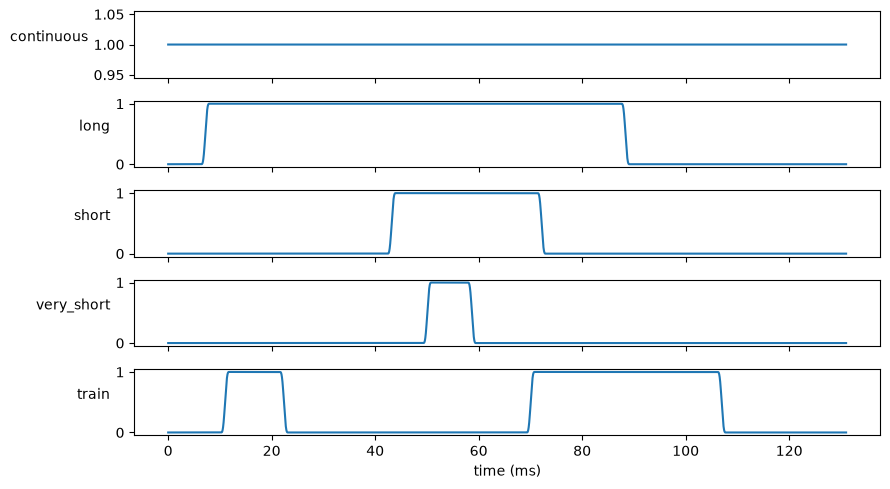

In [5]:
def _ms(v):
    return int(round(v * 1e-3 * FS))


def make_intervals(rng, btype, n):
    # on-intervals [start, end) in samples
    if btype == "continuous":
        return [(0, n)]
    if btype in ("long", "short", "very_short"):
        lo, hi = {"long": (30, 130), "short": (10, 30), "very_short": (2, 10)}[btype]
        d = _ms(rng.uniform(lo, hi))
        if btype != "very_short" and rng.random() < 0.3:
            s0 = int(rng.uniform(-0.5 * d, n - 0.5 * d))             # truncated at an edge
        else:
            s0 = int(rng.uniform(0, max(1, n - d)))
        return [(max(0, s0), min(n, s0 + d))]
    if btype == "train":
        for _ in range(20):
            ints, t = [], _ms(rng.uniform(0, 20))
            while t < n:
                on, gap = _ms(rng.uniform(10, 60)), _ms(rng.uniform(10, 60))
                ints.append((t, min(n, t + on)))
                t += on + gap
            ints = [(a, b) for a, b in ints if b - a >= _ms(3)]
            if len(ints) >= 2:
                return ints
        return [(_ms(10), _ms(40)), (_ms(70), _ms(100))]
    raise ValueError(btype)


def envelope_from_intervals(ints, n):
    ind = np.zeros(n, dtype=np.float64)
    for a, b in ints:
        ind[a:b] = 1.0
    shortest = min(b - a for a, b in ints)
    r = max(3, min(_ms(1.5), int(0.25 * shortest))) | 1                   # odd ramp length
    kern = np.hanning(r + 2)[1:-1]
    kern /= kern.sum()
    padded = np.pad(ind, r // 2, mode="edge")                             # no artificial ramp at the scene edge
    return np.convolve(padded, kern, mode="valid").astype(np.float32)


def obw_bounds(y, frac=CFG.obw_fraction, nfft=1 << 16):
    # 99%-power occupied bandwidth of the ideal (noise-free) signal: lower and upper frequency
    Y = np.fft.fftshift(np.fft.fft(y, nfft))
    p = (Y.real ** 2 + Y.imag ** 2)
    c = np.cumsum(p) / p.sum()
    freqs = (np.arange(nfft) - nfft // 2) * FS / nfft
    lo = freqs[min(np.searchsorted(c, (1 - frac) / 2), nfft - 1)]
    hi = freqs[min(np.searchsorted(c, 1 - (1 - frac) / 2), nfft - 1)]
    return float(lo), float(hi)


# quick look at the envelopes
_rng = np.random.default_rng(1)
fig, ax = plt.subplots(5, 1, figsize=(9, 5), sharex=True)
for a, bt in zip(ax, CFG.burst_types):
    ints = make_intervals(_rng, bt, NS)
    a.plot(np.arange(NS) / FS * 1e3, envelope_from_intervals(ints, NS))
    a.set_ylabel(bt, rotation=0, ha="right")
ax[-1].set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

## 5. Receiver model and spectrogram

A **single STFT implementation** is used for generation, QA and (later) training and inference, so train/serve skew cannot occur.

Spectrogram values are stored as `uint8` dB **relative to the expected noise floor** (0 dB = unit-variance complex noise, the same reference for every scene), quantized between `db_min` and `db_max`.

Receiver chain applied to each scene (R&D 3.3): signals (faded, frequency-shifted by the transmitter offset and the receiver's common frequency offset) + AWGN + optional hard negatives, then band-edge roll-off, IQ imbalance, DC offset and an AGC + ADC quantizer (8, 12 or 14 bit).

In [6]:
WIN = get_window("hann", CFG.n_fft).astype(np.float32)
WIN_ENERGY = float(np.sum(WIN.astype(np.float64) ** 2))


def spectrogram_pow(x):
    # linear power, shape [frames, bins], bins in ascending frequency (-fs/2 .. +fs/2), 1.0 = unit-variance noise floor
    fr = sliding_window_view(x, CFG.n_fft)[::CFG.hop]
    X = np.fft.fft(fr * WIN, axis=-1)
    return np.fft.fftshift(X.real ** 2 + X.imag ** 2, axes=-1) / WIN_ENERGY


def spectrogram_db(x):
    return (10 * np.log10(spectrogram_pow(x) + 1e-12)).astype(np.float32)


DB_STEP = (CFG.db_max - CFG.db_min) / 255.0


def quantize_db(db):
    return np.clip(np.round((db - CFG.db_min) / DB_STEP), 0, 255).astype(np.uint8)


def dequantize_db(q):
    return q.astype(np.float32) * DB_STEP + CFG.db_min


@lru_cache(maxsize=4)
def rx_filter_response(n):
    # flat to 80% of the band, then a raised-cosine roll-off to -20 dB at the band edge (analog + decimation filter)
    a = np.abs(np.fft.fftfreq(n, 1 / FS)) / (FS / 2)
    h = np.ones(n)
    m = a > 0.8
    h[m] = 0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * (a[m] - 0.8) / 0.2))
    return h


def fading_gain(rng, n, level):
    # flat fading (narrowband VHF/UHF): 0 none, 1 Rician K=10 dB, 2 Rician K=3 dB, 3 Rayleigh. Unit mean power.
    if level == 0:
        return np.ones(n, dtype=np.complex64)
    K = {1: 10 ** 1.0, 2: 10 ** 0.3, 3: 0.0}[level]
    fd, m = rng.uniform(2, 20), 16
    t = np.arange(n) / FS
    ang, ph = rng.uniform(0, 2 * np.pi, m), rng.uniform(0, 2 * np.pi, m)
    diffuse = np.exp(1j * (2 * np.pi * fd * np.cos(ang)[:, None] * t[None, :] + ph[:, None])).sum(0) / np.sqrt(m)
    return (np.sqrt(K / (K + 1)) + np.sqrt(1 / (K + 1)) * diffuse).astype(np.complex64)


def adc_quantize(x, bits, headroom_db):
    # AGC puts full scale at headroom_db above the composite rms, then rounds to `bits` bits (I and Q separately).
    rms = np.sqrt(np.mean(np.abs(x) ** 2))
    fs_amp = rms * 10 ** (headroom_db / 20)
    step = 2 * fs_amp / 2 ** bits
    lim = 2 ** (bits - 1)
    qi = np.clip(np.round(x.real / step), -lim, lim - 1).astype(np.int32)
    qr = np.clip(np.round(x.imag / step), -lim, lim - 1).astype(np.int32)
    shift = 16 - bits                                       # store left-aligned in int16
    iq = np.stack([qi << shift, qr << shift], axis=-1).astype(np.int16)
    return iq, float(step / 2 ** shift)                     # int16 LSB -> noise-floor units


def iq_to_complex(iq, scale):
    return ((iq[..., 0].astype(np.float32) + 1j * iq[..., 1].astype(np.float32)) * scale).astype(np.complex64)


def to_pixel_box(f_lo, f_hi, s0, s1):
    # frequency bins covered by [f_lo, f_hi]; time frames whose window CENTER lies inside the on-interval (min 2 frames)
    F, T = CFG.n_fft, CFG.n_frames
    i0 = int(np.clip(round(f_lo / DF + F / 2), 0, F - 1))
    i1 = int(np.clip(max(round(f_hi / DF + F / 2), i0), 0, F - 1))
    k0 = max(int(np.ceil((s0 - CFG.n_fft / 2) / CFG.hop)), 0)
    k1 = min(int(np.floor((s1 - 1 - CFG.n_fft / 2) / CFG.hop)), T - 1)
    if k1 < k0 + 1:
        k0 = max(0, min(k0, T - 2))
        k1 = k0 + 1
    return i0, k0, i1, k1

## 6. Scene composer

Three scene modes besides the normal one:

- **general**: 0 to 4 signals (family-balanced classes, burst profile, SNR in 5 to 30 dB). In `train` the SNR density falls with SNR (more low-SNR data); `val`/`test` draw it uniformly so every SNR bin has enough samples for per-SNR reporting.
- **pair** (`test_1khz`): exactly two signals with a controlled center-frequency spacing (250 Hz to 10 kHz, 40% at exactly 1 kHz), bandwidth tier T1/T2/T3 (R&D 2.2), SNR sweep, and a controlled time overlap (2 to 130 ms). Transmitter offsets are zero in this mode so the spacing is exact; the receiver's common offset shifts both signals equally.
- **openset**: 1 to 3 signals, at least one from a held-out class.
- **snr_stress**: SNR drawn outside 5 to 30 dB (robustness reporting only).

**SNR convention (R&D 2.5):** `0.99 * P_on / (sigma^2 * B_ref / fs) = SNR`, with `sigma^2 = 1`, `P_on` the mean power while the signal is on, and `B_ref = max(OBW, 500 Hz)`.

**Labels** are derived from the generator state: box frequency = the lower and upper bounds that hold 99% of the noise-free signal power (equal to `center +- OBW/2` for symmetric signals; a short piece of a chirp is not symmetric), minimum one bin, box time = frames whose window center lies inside the on-interval. Each burst of a train is its own box.

In [7]:
PAIR_SEPS = [250, 500, 750, 1000, 1500, 2000, 3000, 5000, 10000]
PAIR_SEP_P = [0.08, 0.08, 0.08, 0.40, 0.08, 0.08, 0.08, 0.08, 0.04]
PAIR_OVERLAP_MS = [2, 5, 10, 20, 50, 130]                  # 130 = both signals on for the whole scene
PAIR_OVERLAP_P = [0.08, 0.08, 0.12, 0.14, 0.18, 0.40]
PAIR_POOL_NARROW = ["CW", "BPSK", "QPSK", "2-FSK", "GMSK"]
PAIR_RS = {"T1": (100, 300), "T2": (300, 700)}


def sample_snr(rng, lo, hi, tau=None):
    # uniform in [lo, hi], or a truncated exponential from lo with scale tau (dB). Both consume exactly one rng draw,
    # so switching a set between them never shifts the random stream of anything else in the scene.
    u = rng.uniform()
    if tau is None:
        return float(lo + u * (hi - lo))
    return float(lo - tau * np.log(1.0 - u * (1.0 - np.exp(-(hi - lo) / tau))))


def plan_scene(rng, spec):
    mode, forced = spec["mode"], spec.get("force")
    plans, extra = [], {}
    snr_lo, snr_hi = CFG.snr_range
    if forced:                                              # explicit classes (previews and unit tests)
        for f in forced:
            plans.append(dict(cls=f["cls"], snr=f["snr_db"], btype=f.get("btype", "continuous"), intervals=None, rs_override=None))
    elif mode == "pair":
        sep = float(rng.choice(PAIR_SEPS, p=PAIR_SEP_P))
        tier = str(rng.choice(["T1", "T2", "T3"], p=[0.4, 0.3, 0.3]))
        ov = float(rng.choice(PAIR_OVERLAP_MS, p=PAIR_OVERLAP_P))
        if ov >= 130:
            ints = [(0, NS)]
        else:
            d = _ms(ov)
            s0 = int(rng.integers(0, NS - d))
            ints = [(s0, s0 + d)]
        pool = KNOWN if tier == "T3" else PAIR_POOL_NARROW
        for _ in range(2):
            c = pool[int(rng.integers(len(pool)))]
            plans.append(dict(cls=c, snr=float(rng.uniform(snr_lo, snr_hi)), btype="continuous" if ov >= 130 else "overlap", intervals=ints,
                              rs_override=None if tier == "T3" else PAIR_RS[tier]))
        extra = dict(sep_hz=sep, tier_target=tier, overlap_ms=ov)
    elif mode == "openset":
        n_sig = int(rng.integers(1, 4))
        for k in range(n_sig):
            unk = (k == 0) or rng.random() < 0.3
            c = UNKNOWN[int(rng.integers(len(UNKNOWN)))] if unk else sample_known_class(rng)
            plans.append(dict(cls=c, snr=float(rng.uniform(snr_lo, snr_hi)), btype=str(rng.choice(CFG.burst_types, p=CFG.burst_probs)),
                              intervals=None, rs_override=None))
    else:
        n_sig = int(rng.choice(len(CFG.n_signals_probs), p=CFG.n_signals_probs)) if mode == "general" else int(rng.integers(1, 4))
        snr_tau = CFG.snr_tau_train if (spec["set"] == "train" and mode == "general") else None
        for _ in range(n_sig):
            if mode == "snr_stress":
                lo, hi = CFG.snr_stress_ranges[int(rng.integers(len(CFG.snr_stress_ranges)))]
            else:
                lo, hi = snr_lo, snr_hi
            plans.append(dict(cls=sample_known_class(rng, TRAIN_BOOST if spec["set"] == "train" and mode == "general" else None),
                              snr=sample_snr(rng, lo, hi, snr_tau),
                              btype=str(rng.choice(CFG.burst_types, p=CFG.burst_probs)), intervals=None, rs_override=None))
    return plans, extra


def snr_amplitude(obw, p_on, snr_db):
    # amplitude that gives the requested in-band SNR against unit-variance complex noise (see convention above)
    b_ref = max(obw, CFG.ref_bw_min_hz)
    return float(np.sqrt(10 ** (snr_db / 10) * b_ref / FS / (CFG.obw_fraction * p_on))), b_ref


def _tier_from_obw(obw_max):
    return "T1" if obw_max <= 500 else ("T2" if obw_max <= 1000 else "T3")


def make_scene(spec, keep_components=False):
    cfg = CFG
    rng = np.random.default_rng(spec["seed"])
    sess = spec["session"]
    plans, extra = plan_scene(rng, spec)

    # 1) generate every signal: baseband, envelope, occupied bandwidth, SNR scaling, fading
    sigs = []
    for p in plans:
        ints = p["intervals"] or make_intervals(rng, p["btype"], NS)
        env = envelope_from_intervals(ints, NS)
        min_rs = cfg.min_symbols / (min(b - a for a, b in ints) / FS)
        x, info = gen_signal(rng, p["cls"], NS, min_rs=min_rs, rs_override=p["rs_override"])
        y = x * env
        p_on = float(np.sum(np.abs(y) ** 2) / np.sum(env.astype(np.float64) ** 2))
        lo, hi = obw_bounds(y)
        obw = hi - lo
        amp, b_ref = snr_amplitude(obw, p_on, p["snr"])
        z = (y * amp * fading_gain(rng, NS, sess["fading_level"])).astype(np.complex64)
        sigs.append(dict(plan=p, ints=ints, info=info, z=z, obw=obw, lo=lo, hi=hi, ext=max(abs(lo), abs(hi)), b_ref=b_ref))

    # 2) place the signals in frequency
    if spec["mode"] == "pair" and not spec.get("force"):
        sep = extra["sep_hz"]
        allowed = max(0.0, FS / 2 - cfg.guard_hz - max(s["ext"] for s in sigs) - sep / 2)
        mid = float(rng.uniform(-allowed, allowed))
        order = rng.permutation(2)
        for s, o in zip(sigs, order):
            s["fc_nom"], s["tx_off"] = mid + (o - 0.5) * sep, 0.0
    else:
        placed = []
        for s in sigs:
            allowed = max(0.0, FS / 2 - cfg.guard_hz - s["ext"])
            tx = float(np.clip(rng.normal(0, 300.0), -1000, 1000))
            for _ in range(40):
                fc = float(rng.uniform(-allowed, allowed))
                if all(abs(fc + tx - q) >= DF for q in placed):
                    break
            placed.append(fc + tx)
            s["fc_nom"], s["tx_off"] = fc, tx
    cfo = float(sess["cfo_hz"] + rng.normal(0, 20.0))        # receiver common offset (oscillator ppm x carrier)
    t = np.arange(NS) / FS
    sig_sum = np.zeros(NS, dtype=np.complex64)
    comps = []
    for s in sigs:
        s["fc"] = s["fc_nom"] + s["tx_off"] + cfo
        zs = (s["z"] * np.exp(2j * np.pi * s["fc"] * t)).astype(np.complex64)
        sig_sum += zs
        if keep_components:
            comps.append(zs)

    # 3) noise and hard negatives (spurs and impulses are NOT labeled; they test false alarms)
    rx = sig_sum + ((rng.standard_normal(NS) + 1j * rng.standard_normal(NS)) / np.sqrt(2)).astype(np.complex64)
    interf = []
    if rng.random() < (0.5 if len(sigs) == 0 else cfg.hard_negative_prob):
        if rng.random() < 0.5:
            fc = float(rng.uniform(-(FS / 2 - cfg.guard_hz), FS / 2 - cfg.guard_hz))
            snr = float(rng.uniform(0, 4))
            amp, _ = snr_amplitude(0.0, 1.0, snr)
            rx += (amp * np.exp(2j * np.pi * fc * t + 1j * rng.uniform(0, 2 * np.pi))).astype(np.complex64)
            interf.append(dict(kind="spur", center_hz=fc, snr_db=snr))
        else:
            for _ in range(int(rng.integers(2, 6))):
                pos, w = int(rng.integers(0, NS - 8)), int(rng.integers(1, 5))
                rx[pos:pos + w] += np.complex64(rng.uniform(15, 40) * np.exp(1j * rng.uniform(0, 2 * np.pi)))
            interf.append(dict(kind="impulse"))

    # 4) receiver chain
    rx = np.fft.ifft(np.fft.fft(rx) * rx_filter_response(NS)).astype(np.complex64)
    kappa = 10 ** (-sess["irr_db"] / 20) * np.exp(1j * sess["kappa_phase"])
    rx = (rx + kappa * np.conj(rx)).astype(np.complex64)
    rx = rx + np.complex64(sess["dc_rel"] * np.exp(1j * sess["dc_phase"]))
    iq, iq_scale = adc_quantize(rx, sess["adc_bits"], cfg.adc_headroom_db)
    spec_u8 = quantize_db(spectrogram_db(iq_to_complex(iq, iq_scale)))

    # 5) labels
    mask = np.zeros((cfg.n_frames, cfg.n_fft), dtype=np.uint8)
    rows = []
    for k, s in enumerate(sigs):
        c = CLASS[s["plan"]["cls"]]
        f_lo, f_hi = s["fc"] + s["lo"], s["fc"] + s["hi"]          # bounds holding 99% of the signal power
        if f_hi - f_lo < DF:                                      # at least one bin wide (CW)
            mid = (f_lo + f_hi) / 2
            f_lo, f_hi = mid - DF / 2, mid + DF / 2
        for b, (a0, a1) in enumerate(s["ints"]):
            x0, y0, x1, y1 = to_pixel_box(f_lo, f_hi, a0, a1)
            mask[y0:y1 + 1, x0:x1 + 1] = FAMILY_ID[c["family"]]
            rows.append(dict(
                scene_id=spec["scene_id"], set=spec["set"], sig_idx=k, burst_idx=b,
                class_id=c["id"], class_name=c["name"], family=c["family"], family_id=FAMILY_ID[c["family"]],
                coarse=c["coarse"], coarse_id=COARSE_ID[c["coarse"]],
                center_hz=s["fc"], obw_hz=s["obw"], f_lo_hz=f_lo, f_hi_hz=f_hi,
                t_start_s=a0 / FS, t_end_s=a1 / FS, burst_type=s["plan"]["btype"], snr_db=s["plan"]["snr"],
                snr_ref_bw_hz=s["b_ref"], baud=s["info"].get("baud", np.nan), tx_offset_hz=s["tx_off"],
                fading_level=sess["fading_level"], params_json=json.dumps(s["info"], default=float),
                box_x0=x0, box_y0=y0, box_x1=x1, box_y1=y1))
    scene = dict(
        scene_id=spec["scene_id"], set=spec["set"], index=spec["index"], group_id=spec["group_id"], seed=spec["seed"],
        mode=spec["mode"], n_signals=len(sigs), n_boxes=len(rows), n_interferers=len(interf),
        interferers_json=json.dumps(interf, default=float), cfo_hz=cfo, iq_scale=iq_scale,
        rf_hz=sess["rf_hz"], ppm=sess["ppm"], adc_bits=sess["adc_bits"], irr_db=sess["irr_db"], dc_rel=sess["dc_rel"],
        fading_level=sess["fading_level"], spec_sha1=hashlib.sha1(spec_u8.tobytes()).hexdigest()[:16])
    if spec["mode"] == "pair" and not spec.get("force"):
        a, b = sigs
        scene.update(extra)
        scene.update(sep_measured_hz=abs(a["fc"] - b["fc"]),
                     tier_measured=_tier_from_obw(max(max(a["obw"], DF), max(b["obw"], DF))),
                     carrier_bearing=bool({a["plan"]["cls"], b["plan"]["cls"]} & {"CW", "AM"}))
    return dict(spec=spec_u8, mask=mask, iq=iq, scene=scene, signals=rows, components=comps if keep_components else None)

## 7. Capture sessions and set specifications

Scenes are grouped into **sessions** of 50 scenes that share receiver state (RF carrier, oscillator error, ADC bits, IQ imbalance, DC offset, fading level). **Splits never cut a session**, and every set has its own seed range, so there is no leakage by construction.

| Profile | Frequency reference | ADC | Fading | Used by |
|---|---|---|---|---|
| `train` | 0.1 or 2 ppm | 12 or 14 bit | none / Rician K=10 dB / Rician K=3 dB | train, val, test, test_1khz, test_openset, test_snr_stress |
| `hard` (unseen) | 10 ppm | 8 bit | Rayleigh | test_robust |

one scene: 16 ms, spectrogram (128, 1024) uint8, IQ (33536, 2) int16


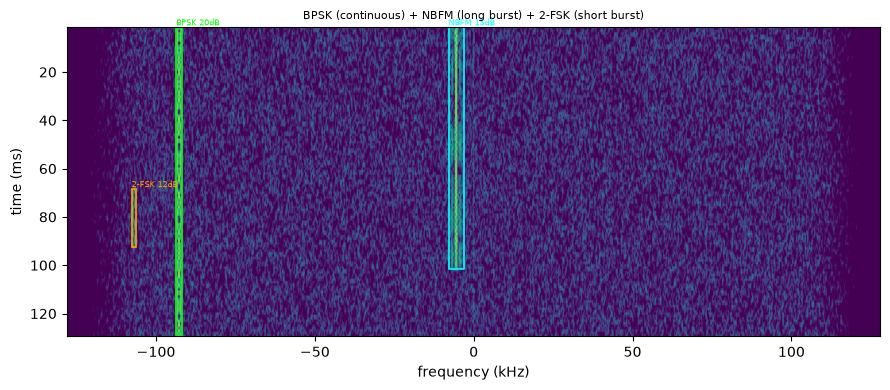

In [8]:
RF_CARRIERS = [121.5e6, 145.5e6, 156.8e6, 435.0e6, 446.1e6]      # airband, 2 m, marine, 70 cm, PMR446 (metadata; baseband is identical)


def session_for_group(set_id, group, profile):
    r = np.random.default_rng(np.random.SeedSequence([CFG.base_seed, set_id, group, 777]))
    rf = float(r.choice(RF_CARRIERS))
    if profile == "train":
        ppm, bits = float(r.choice([0.1, 2.0], p=[0.4, 0.6])), int(r.choice([12, 14], p=[0.6, 0.4]))
        irr, dc, fad = float(r.uniform(30, 50)), float(r.uniform(0.0, 0.2)), int(r.choice([0, 1, 2], p=[0.5, 0.3, 0.2]))
    else:
        ppm, bits = 10.0, 8
        irr, dc, fad = float(r.uniform(20, 30)), float(r.uniform(0.2, 0.5)), 3
    return dict(rf_hz=rf, ppm=ppm, cfo_hz=float(r.uniform(-ppm, ppm) * 1e-6 * rf), adc_bits=bits, irr_db=irr,
                dc_rel=dc, fading_level=fad, kappa_phase=float(r.uniform(0, 2 * np.pi)), dc_phase=float(r.uniform(0, 2 * np.pi)))


def make_specs(set_name, start=0, stop=None):
    n_total, sid = SET_SIZES[set_name], SET_IDS[set_name]
    stop = n_total if stop is None else min(stop, n_total)
    mode = SET_MODE.get(set_name, "general")
    profile = "hard" if set_name == "test_robust" else "train"
    sessions, specs = {}, []
    for i in range(start, stop):
        g = i // CFG.group_size
        if g not in sessions:
            sessions[g] = session_for_group(sid, g, profile)
        seed = int(np.random.SeedSequence([CFG.base_seed, sid, i]).generate_state(1, np.uint64)[0])
        specs.append(dict(set=set_name, scene_id=f"{set_name}_{i:07d}", index=i, group_id=f"{set_name}_g{g:05d}",
                          seed=seed, mode=mode, session=sessions[g]))
    return specs


# one scene per family for a first look: spectrogram with the automatic boxes drawn on top
FAM_COLORS = {1: "white", 2: "yellow", 3: "cyan", 4: "lime", 5: "magenta", 6: "orange", 7: "red"}


def plot_scene(sc, ax=None, title=None, xlim=None):
    ax = ax or plt.gca()
    db = dequantize_db(sc["spec"])
    ext = [(-CFG.n_fft / 2 - 0.5) * DF / 1e3, (CFG.n_fft / 2 - 0.5) * DF / 1e3,
           ((CFG.n_frames - 1) * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3, (CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3]
    ax.imshow(db, aspect="auto", extent=ext, cmap="viridis", vmin=-5, vmax=30)
    for r in sc["signals"]:
        f0 = (r["box_x0"] - CFG.n_fft / 2 - 0.5) * DF / 1e3
        f1 = (r["box_x1"] - CFG.n_fft / 2 + 0.5) * DF / 1e3
        t0 = (r["box_y0"] * CFG.hop + CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3
        t1 = (r["box_y1"] * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec=FAM_COLORS[r["family_id"]], lw=1.2))
        ax.text(f0, t0, f'{r["class_name"]} {r["snr_db"]:.0f}dB', color=FAM_COLORS[r["family_id"]], fontsize=6, va="bottom")
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.set_xlabel("frequency (kHz)")
    ax.set_ylabel("time (ms)")
    ax.set_title(title or sc["scene"]["scene_id"], fontsize=8)


_demo = make_specs("train", 0, 1)[0]
_demo["force"] = [dict(cls="BPSK", snr_db=20, btype="continuous"), dict(cls="NBFM", snr_db=15, btype="long"),
                  dict(cls="2-FSK", snr_db=12, btype="short")]
_t0 = time.time()
_sc = make_scene(_demo)
print(f"one scene: {(time.time() - _t0) * 1e3:.0f} ms, spectrogram {_sc['spec'].shape} uint8, IQ {_sc['iq'].shape} int16")
plt.figure(figsize=(9, 4))
plot_scene(_sc, title="BPSK (continuous) + NBFM (long burst) + 2-FSK (short burst)")
plt.tight_layout()
plt.show()

## 8. Simulator validation (before generating any data)

R&D Section 8 requires checking the simulator against theory. Four checks:

1. **Noise floor:** unit-variance complex noise must sit at 0 dB in the spectrogram.
2. **SNR convention:** the measured in-band SNR of a scaled signal must match the requested SNR.
3. **1 kHz resolvability:** two tones 1 kHz apart must show two peaks with a clear valley with this STFT setting (and 500 Hz must not).
4. **Modulator and pulse shaping:** BPSK bit-error rate against the theoretical `0.5 * erfc(sqrt(Es/N0))`.

In [9]:
from math import erfc, sqrt

rng = np.random.default_rng(0)

# 1) noise floor
mp_ = np.mean([spectrogram_pow(((rng.standard_normal(NS) + 1j * rng.standard_normal(NS)) / np.sqrt(2)).astype(np.complex64)).mean() for _ in range(20)])
print(f"1) noise floor: mean power = {10 * np.log10(mp_):+.3f} dB (expected 0 dB)")
assert abs(10 * np.log10(mp_)) < 0.1

# 2) SNR convention
def measured_snr_db(cls, target_db, trials=30):
    vals = []
    for _ in range(trials):
        x, _ = gen_signal(rng, cls, NS)
        lo, hi = obw_bounds(x)
        obw = hi - lo
        p_on = float(np.mean(np.abs(x) ** 2))
        amp, b_ref = snr_amplitude(obw, p_on, target_db)
        rx = amp * x + (rng.standard_normal(NS) + 1j * rng.standard_normal(NS)) / np.sqrt(2)
        P = np.abs(np.fft.fft(rx)) ** 2 / NS ** 2
        f = np.fft.fftfreq(NS, 1 / FS)
        band = np.abs(f) <= b_ref / 2
        noise_band = np.abs(np.abs(f) - 90_000) <= b_ref / 2          # an empty region of the same width
        sn, nn = P[band].sum(), P[noise_band].sum() / 2               # two symmetric noise regions
        vals.append(10 * np.log10(max(sn - nn, 1e-12) / nn))
    return float(np.mean(vals))

for cls in ["QPSK", "NBFM", "CW", "2-FSK"]:
    m = measured_snr_db(cls, 15.0)
    print(f"2) {cls:6s} target 15.0 dB -> measured {m:5.2f} dB")
    assert abs(m - 15.0) < 0.8, cls

# 3) two-tone resolution with this STFT (worst case: tones straddle bin centers)
def valley_depth_db(sep, offset):
    t = np.arange(NS) / FS
    x = (np.exp(2j * np.pi * offset * t) + np.exp(2j * np.pi * (offset + sep) * t)).astype(np.complex64)
    P = spectrogram_pow(x).mean(0)
    k1, k2 = int(round(offset / DF + CFG.n_fft / 2)), int(round((offset + sep) / DF + CFG.n_fft / 2))
    peak = min(P[k1 - 1:k1 + 2].max(), P[k2 - 1:k2 + 2].max())
    return 10 * np.log10(peak / P[k1:k2 + 1].min())

tab = pd.DataFrame({sep: [valley_depth_db(sep, o) for o in (0.0, 0.5 * DF)] for sep in (250, 500, 750, 1000, 1500)},
                   index=["tones on bin centers", "tones half a bin off"]).round(1)
print("3) valley depth between two equal tones (dB), Hann window, 250 Hz bins:")
display(tab)
assert (tab[1000] > 6).all(), "1 kHz tones must be resolvable with the chosen STFT"

# 4) BPSK BER against theory
def bpsk_ber(esn0_db, n_sym=300_000, sps=8, beta=0.35):
    r = np.random.default_rng(5)
    n = n_sym * sps
    x, sym, start, taps = linear_core(r, CONST["BPSK"], sps, beta, n)
    s2 = 10 ** (-esn0_db / 10)                                         # Es = 1, N0 = sigma^2
    m = fftconvolve(x + (r.standard_normal(n) + 1j * r.standard_normal(n)) * np.sqrt(s2 / 2), taps, mode="full")
    n_t = len(taps) - 1
    idx = np.arange(len(sym)) * sps + n_t - start
    ok = (idx >= n_t) & (idx < n - n_t)
    return float(np.mean(np.sign(m.real[idx[ok]]) != sym.real[ok]))

rows = []
for e in (0, 2, 4, 6):
    rows.append(dict(EsN0_dB=e, measured=bpsk_ber(e), theory=0.5 * erfc(sqrt(10 ** (e / 10)))))
ber = pd.DataFrame(rows)
ber["ratio"] = ber.measured / ber.theory
print("4) BPSK BER with RRC pulse shaping and matched filter:")
display(ber)
assert ber.ratio.between(0.85, 1.15).all()
print("simulator validation passed")

1) noise floor: mean power = -0.001 dB (expected 0 dB)
2) QPSK   target 15.0 dB -> measured 15.05 dB


2) NBFM   target 15.0 dB -> measured 15.02 dB


2) CW     target 15.0 dB -> measured 15.14 dB
2) 2-FSK  target 15.0 dB -> measured 15.08 dB
3) valley depth between two equal tones (dB), Hann window, 250 Hz bins:


,250,500,750,1000,1500
tones on bin centers,0.0,3.0,6.0,173.0,190.100006
tones half a bin off,2.8,0.2,11.0,15.4,30.400000


4) BPSK BER with RRC pulse shaping and matched filter:


,EsN0_dB,measured,theory,ratio
0,0,0.078560,0.078650,0.998858
1,2,0.037795,0.037506,1.007698
2,4,0.012564,0.012501,1.005041
3,6,0.002413,0.002388,1.010526


simulator validation passed


## 9. Build engine

Scenes are generated in parallel (one shard of 250 scenes per task) and written as:

| File | Content |
|---|---|
| `shard_XXXX_spec.npy` | `uint8 [scene, 128, 1024]` dB relative to the noise floor (memory-mappable) |
| `shard_XXXX_iq.npy` | `int16 [scene, 33536, 2]` raw IQ (left-aligned ADC codes; scale in `scenes` table) |
| `shard_XXXX_mask.npz` | `uint8 [scene, 128, 1024]` family-id pixel mask (0 = background), compressed |
| `scenes.*`, `signals.*` | one row per scene / per labeled box (Parquet if `pyarrow` is installed, else CSV.gz) |
| `coco.json` | detection boxes: `bbox = [x = frequency bin, y = time frame, width, height]`, category = family id |
| `_SUCCESS` | manifest with SHA-256 checksums |

A finished set is **not regenerated** unless you ask for it (`SPECTRUM_REBUILD=name`); frozen test sets also need `SPECTRUM_FORCE_FROZEN=1`.

In [10]:
import shutil


def save_table(df, base):
    base = str(base)
    try:
        df.to_parquet(base + ".parquet", index=False)
        return base + ".parquet"
    except Exception:
        if os.path.exists(base + ".parquet"):
            os.remove(base + ".parquet")
        df.to_csv(base + ".csv.gz", index=False)
        return base + ".csv.gz"


def load_table(base):
    base = str(base)
    if os.path.exists(base + ".parquet"):
        return pd.read_parquet(base + ".parquet")
    return pd.read_csv(base + ".csv.gz")


def sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def build_shard(job):
    set_name, shard_idx, specs, set_dir = job
    n = len(specs)
    spec_arr = np.empty((n, CFG.n_frames, CFG.n_fft), np.uint8)
    mask_arr = np.empty_like(spec_arr)
    iq_arr = np.empty((n, NS, 2), np.int16) if STORE_IQ else None
    scene_rows, sig_rows = [], []
    for j, sp in enumerate(specs):
        out = make_scene(sp)
        spec_arr[j], mask_arr[j] = out["spec"], out["mask"]
        if STORE_IQ:
            iq_arr[j] = out["iq"]
        out["scene"].update(shard=shard_idx, pos=j)
        scene_rows.append(out["scene"])
        for r in out["signals"]:
            r.update(shard=shard_idx, pos=j)
            sig_rows.append(r)
    base = f"{set_dir}/shard_{shard_idx:04d}"
    np.save(base + "_spec.npy", spec_arr)
    if STORE_IQ:
        np.save(base + "_iq.npy", iq_arr)
    np.savez_compressed(base + "_mask.npz", mask=mask_arr)
    return shard_idx, scene_rows, sig_rows


def write_coco(set_dir, scenes, signals):
    images = [dict(id=int(r.index), file_name=f"shard_{int(r.shard):04d}_spec.npy#{int(r.pos)}", width=CFG.n_fft,
                   height=CFG.n_frames, scene_id=r.scene_id) for r in scenes.itertuples()]
    idx_of = dict(zip(scenes.scene_id, scenes["index"]))
    anns = []
    for k, r in enumerate(signals.itertuples()):
        w, h = r.box_x1 - r.box_x0 + 1, r.box_y1 - r.box_y0 + 1
        anns.append(dict(id=k, image_id=int(idx_of[r.scene_id]), category_id=int(r.family_id), bbox=[int(r.box_x0), int(r.box_y0), int(w), int(h)],
                         area=int(w * h), iscrowd=0, class_name=r.class_name, snr_db=float(r.snr_db), burst_type=r.burst_type))
    cats = [dict(id=v, name=k) for k, v in FAMILY_ID.items()]
    with open(f"{set_dir}/coco.json", "w") as f:
        json.dump(dict(images=images, annotations=anns, categories=cats,
                       info=dict(description="x = frequency bin (0 = -fs/2), y = time frame", version=CFG.version)), f)


def run_set(set_name):
    set_dir = OUT_DIR / "sets" / set_name
    if (set_dir / "_SUCCESS").exists():
        if set_name not in REBUILD:
            print(f"[skip] {set_name}: already built")
            return json.loads((set_dir / "_SUCCESS").read_text())
        if set_name in FROZEN_SETS and not FORCE_FROZEN:
            raise RuntimeError(f"{set_name} is a frozen test set; set SPECTRUM_FORCE_FROZEN=1 to regenerate it")
    if set_dir.exists():
        shutil.rmtree(set_dir)                      # rebuild, or leftovers of an interrupted run
    set_dir.mkdir(parents=True)
    t0 = time.time()
    specs = make_specs(set_name)
    jobs = [(set_name, k, specs[i:i + CFG.shard_size], str(set_dir)) for k, i in enumerate(range(0, len(specs), CFG.shard_size))]
    results = []
    if N_WORKERS > 1 and len(jobs) > 1 and "fork" in mp.get_all_start_methods():
        with mp.get_context("fork").Pool(min(N_WORKERS, len(jobs))) as pool:
            for r in tqdm(pool.imap_unordered(build_shard, jobs), total=len(jobs), desc=set_name):
                results.append(r)
    else:
        for job in tqdm(jobs, desc=set_name):
            results.append(build_shard(job))
    results.sort(key=lambda r: r[0])
    scenes = pd.DataFrame([row for _, sc, _ in results for row in sc])
    signals = pd.DataFrame([row for _, _, sg in results for row in sg])
    save_table(scenes, set_dir / "scenes")
    save_table(signals, set_dir / "signals")
    write_coco(set_dir, scenes, signals)
    files = sorted(p for p in set_dir.iterdir() if p.is_file())
    manifest = dict(set=set_name, version=CFG.version, profile=PROFILE, frozen=set_name in FROZEN_SETS, n_scenes=len(scenes),
                    n_boxes=len(signals), n_groups=int(scenes.group_id.nunique()), seconds=round(time.time() - t0, 1),
                    built_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
                    checksums={p.name: sha256_file(p) for p in files},
                    bytes=int(sum(p.stat().st_size for p in files)))
    (set_dir / "_SUCCESS").write_text(json.dumps(manifest, indent=1))
    return manifest

## 10. Generate the dataset

Run time scales linearly with the number of scenes and (nearly) with the number of workers. Disk use is about 0.13 MB per scene for the spectrogram plus 0.13 MB for the raw IQ (if stored).

In [11]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "config.json").write_text(json.dumps(dict(
    config=asdict(CFG), profile=PROFILE, set_sizes=SET_SIZES, store_iq=STORE_IQ, db_step=DB_STEP,
    frozen_sets=sorted(FROZEN_SETS), classes=CLASS_TABLE + UNKNOWN_TABLE, family_id=FAMILY_ID, coarse_id=COARSE_ID,
    pair=dict(seps_hz=PAIR_SEPS, sep_p=PAIR_SEP_P, overlap_ms=PAIR_OVERLAP_MS, overlap_p=PAIR_OVERLAP_P),
    software=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__),
    created_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")), indent=1, default=str))

est_gb = sum(SET_SIZES.values()) * (CFG.n_frames * CFG.n_fft * 1.1 + (NS * 4 if STORE_IQ else 0)) / 1e9
print(f"about {est_gb:.1f} GB will be written to {OUT_DIR}")

t_all = time.time()
manifests = {name: run_set(name) for name in SET_SIZES}
print(f"\ntotal wall time {time.time() - t_all:.0f} s")
pd.DataFrame([dict(set=m["set"], scenes=m["n_scenes"], boxes=m["n_boxes"], groups=m["n_groups"], GB=round(m["bytes"] / 1e9, 2),
                   build_s=m["seconds"], frozen=m["frozen"]) for m in manifests.values()])

about 4.2 GB will be written to dataset_boost/spectrum_rf_v0.2.0_pilot


train:   0%|                                                                                                                                                                              | 0/28 [00:00<?, ?it/s]

train:   4%|█████▉                                                                                                                                                                | 1/28 [00:03<01:23,  3.11s/it]

train:   7%|███████████▊                                                                                                                                                          | 2/28 [00:03<00:38,  1.47s/it]

train:  11%|█████████████████▊                                                                                                                                                    | 3/28 [00:03<00:22,  1.11it/s]

train:  18%|█████████████████████████████▋                                                                                                                                        | 5/28 [00:03<00:10,  2.30it/s]

... (45 outputs left out)

test_snr_stress:  75%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▊                                       | 3/4 [00:04<00:01,  1.17s/it]

test_snr_stress: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:04<00:00,  1.05s/it]


total wall time 39 s


,set,scenes,boxes,groups,GB,build_s,frozen
0,train,7000,15091,140,1.86,10.0,False
1,val,1500,3218,30,0.40,5.0,False
2,test,1500,3151,30,0.40,4.2,True
3,test_1khz,2000,4000,40,0.53,4.1,True
4,test_robust,1000,2144,20,0.27,5.3,True
5,test_openset,1000,2320,20,0.27,4.2,True
6,test_snr_stress,1000,2265,20,0.27,4.3,True


## 11. Quality assurance (R&D 3.4)

Automatic checks on the written data:

1. **Structure:** counts, box bounds, valid class ids, family consistency, SNR ranges per set, unknown classes only in `test_openset`, unique seeds, no group shared between sets.
2. **Label correctness:** for a sample of scenes the generator is re-run with `keep_components=True`, and the share of each signal's **noise-free** spectrogram energy that falls inside its labeled box is measured (independent of SNR).
3. **Determinism:** regenerated scenes must reproduce the stored spectrograms bit for bit.
4. **Visual inspection:** boxes drawn on random stored spectrograms.

In [12]:
def read_tables(set_name):
    d = OUT_DIR / "sets" / set_name
    return load_table(d / "scenes"), load_table(d / "signals")


issues = []
all_scenes = []
box_cols = ["box_x0", "box_y0", "box_x1", "box_y1"]
for name in SET_SIZES:
    sc, sg = read_tables(name)
    all_scenes.append(sc)
    if len(sc) != SET_SIZES[name]:
        issues.append(f"{name}: {len(sc)} scenes, expected {SET_SIZES[name]}")
    if len(sg):
        if not ((sg.box_x0 >= 0) & (sg.box_x1 < CFG.n_fft) & (sg.box_x1 >= sg.box_x0) & (sg.box_y0 >= 0) & (sg.box_y1 < CFG.n_frames) & (sg.box_y1 > sg.box_y0)).all():
            issues.append(f"{name}: box outside the image or empty")
        if sg[box_cols + ["center_hz", "obw_hz", "snr_db", "t_start_s", "t_end_s"]].isna().any().any():
            issues.append(f"{name}: NaN in label columns")
        if not (sg.t_end_s > sg.t_start_s).all():
            issues.append(f"{name}: non-positive burst duration")
        fam_of = {n: FAMILY_ID[CLASS[n]["family"]] for n in CLASS}
        if not (sg.class_name.map(fam_of) == sg.family_id).all():
            issues.append(f"{name}: family id inconsistent with class")
        snr_ok = sg.snr_db.between(*CFG.snr_range) if name != "test_snr_stress" else ~sg.snr_db.between(*CFG.snr_range)
        if not snr_ok.all():
            issues.append(f"{name}: SNR outside the intended range")
        if name != "test_openset" and (sg.class_id >= 11).any():
            issues.append(f"{name}: held-out class present")
        if name == "test_openset" and not (sg.groupby("scene_id").class_id.max() >= 11).all():
            issues.append("test_openset: scene without a held-out class")
allsc = pd.concat(all_scenes)
if allsc.seed.duplicated().any():
    issues.append("duplicate seeds")
grp_sets = allsc.groupby("group_id").set.nunique()
if (grp_sets > 1).any():
    issues.append("a session group appears in more than one set (leakage)")
print("structural QA:", "OK" if not issues else issues)
assert not issues

structural QA: OK


In [13]:
def energy_fraction_qa(set_name, n_scenes, seed=0):
    r = np.random.default_rng(seed)
    out = []
    for i in r.choice(SET_SIZES[set_name], min(n_scenes, SET_SIZES[set_name]), replace=False):
        sc = make_scene(make_specs(set_name, int(i), int(i) + 1)[0], keep_components=True)
        for k, comp in enumerate(sc["components"]):
            P = spectrogram_pow(comp)
            m = np.zeros(P.shape, bool)
            for row in sc["signals"]:
                if row["sig_idx"] == k:
                    m[row["box_y0"]:row["box_y1"] + 1, row["box_x0"]:row["box_x1"] + 1] = True
            first = next(rw for rw in sc["signals"] if rw["sig_idx"] == k)
            out.append(dict(set=set_name, scene_id=sc["scene"]["scene_id"], class_name=first["class_name"], burst_type=first["burst_type"],
                            snr_db=first["snr_db"], frac=float(P[m].sum() / P.sum())))
    return pd.DataFrame(out)


n_qa = 60 if PROFILE == "smoke" else 200
qa = pd.concat([energy_fraction_qa(s, n_qa) for s in ("train", "test_1khz", "test_openset")])
summary = qa.groupby("burst_type").frac.describe(percentiles=[0.1, 0.5]).round(3)[["count", "10%", "50%", "min"]]
print("share of a signal's noise-free spectrogram energy inside its labeled box:")
display(summary)
display(qa.groupby("class_name").frac.median().round(3).to_frame("median").T)
assert qa.frac.median() > 0.90, "labels do not enclose the signal energy"
assert qa[qa.burst_type.isin(["continuous", "long"])].frac.median() > 0.93

share of a signal's noise-free spectrogram energy inside its labeled box:


,count,10%,50%,min
burst_type,,,,
continuous,427.0,0.908,0.991,0.809
long,176.0,0.928,0.987,0.832
overlap,250.0,0.811,0.952,0.721
short,167.0,0.960,0.977,0.931
train,82.0,0.970,0.982,0.897
very_short,74.0,0.857,0.931,0.797


class_name,16QAM,2-FSK,4-FSK,64QAM,8-FSK,8PSK,AM,BPSK,CHIRP,CW,GMSK,NBFM,OQPSK,QPSK
median,0.986,0.967,0.986,0.989,0.986,0.99,0.986,0.958,0.989,0.947,0.97,0.988,0.988,0.962


determinism check: 0 of 20 regenerated scenes differ from the stored data


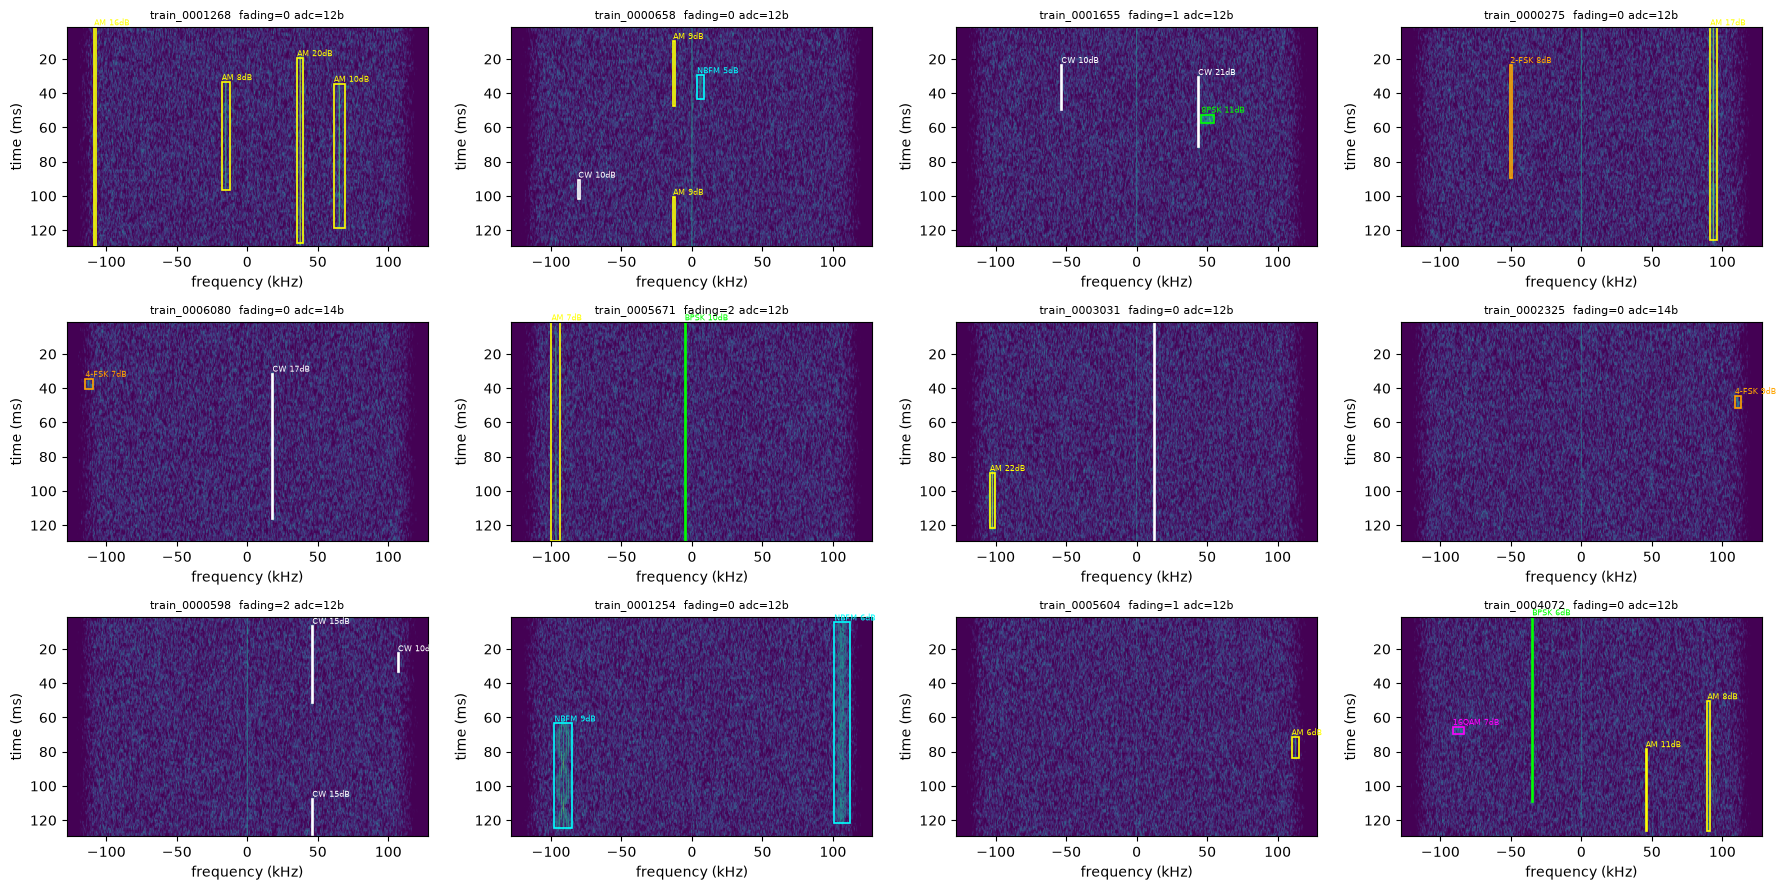

In [14]:
# determinism: regenerate scenes and compare with what is on disk
sc_tr, sg_tr = read_tables("train")
bad = 0
for i in np.random.default_rng(1).choice(len(sc_tr), min(20, len(sc_tr)), replace=False):
    row = sc_tr.iloc[int(i)]
    again = make_scene(make_specs("train", int(row["index"]), int(row["index"]) + 1)[0])
    stored = np.load(OUT_DIR / "sets" / "train" / f"shard_{int(row['shard']):04d}_spec.npy", mmap_mode="r")[int(row["pos"])]
    bad += int(not np.array_equal(again["spec"], stored) or again["scene"]["spec_sha1"] != row["spec_sha1"])
print(f"determinism check: {bad} of 20 regenerated scenes differ from the stored data")
assert bad == 0

# visual inspection of stored data (boxes come from the label tables, not from the generator)
def stored_scene(set_name, row, sg):
    spec = np.load(OUT_DIR / "sets" / set_name / f"shard_{int(row['shard']):04d}_spec.npy", mmap_mode="r")[int(row["pos"])]
    return dict(spec=np.asarray(spec), signals=sg[sg.scene_id == row["scene_id"]].to_dict("records"), scene=dict(scene_id=row["scene_id"]))

fig, axes = plt.subplots(3, 4, figsize=(18, 9))
pick = np.random.default_rng(3).choice(len(sc_tr), 12, replace=False)
for ax, i in zip(axes.ravel(), pick):
    r = sc_tr.iloc[int(i)]
    plot_scene(stored_scene("train", r, sg_tr), ax=ax, title=f'{r["scene_id"]}  fading={r["fading_level"]} adc={r["adc_bits"]}b')
plt.tight_layout()
fig.savefig(OUT_DIR / "qa_overlays_train.png", dpi=110)
plt.show()

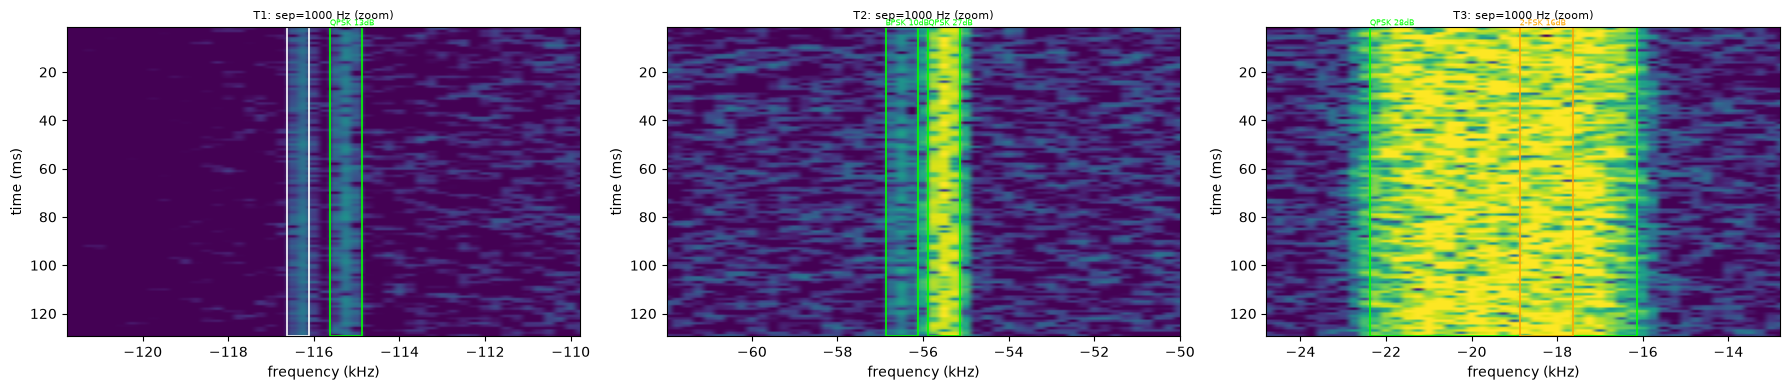

In [15]:
# the 1 kHz set: one pair per bandwidth tier at exactly 1 kHz, zoomed to +-6 kHz around the pair
sc_p, sg_p = read_tables("test_1khz")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, tier in zip(axes, ["T1", "T2", "T3"]):
    cand = sc_p[(sc_p.sep_hz == 1000) & (sc_p.tier_measured == tier) & (sc_p.overlap_ms == 130)]
    if len(cand) == 0:
        ax.set_title(f"{tier}: none"); continue
    r = cand.iloc[0]
    mid = r_c = sg_p[sg_p.scene_id == r["scene_id"]].center_hz.mean() / 1e3
    plot_scene(stored_scene("test_1khz", r, sg_p), ax=ax, title=f'{tier}: sep={r["sep_measured_hz"]:.0f} Hz (zoom)', xlim=(mid - 6, mid + 6))
plt.tight_layout()
plt.show()

## 12. Dataset statistics

,set,scenes,boxes,empty_scenes,with_interferer,groups
0,train,7000,15091,688,1273,140
1,val,1500,3218,120,275,30
2,test,1500,3151,139,292,30
3,test_1khz,2000,4000,0,319,40
4,test_robust,1000,2144,100,192,20
5,test_openset,1000,2320,0,157,20
6,test_snr_stress,1000,2265,0,146,20


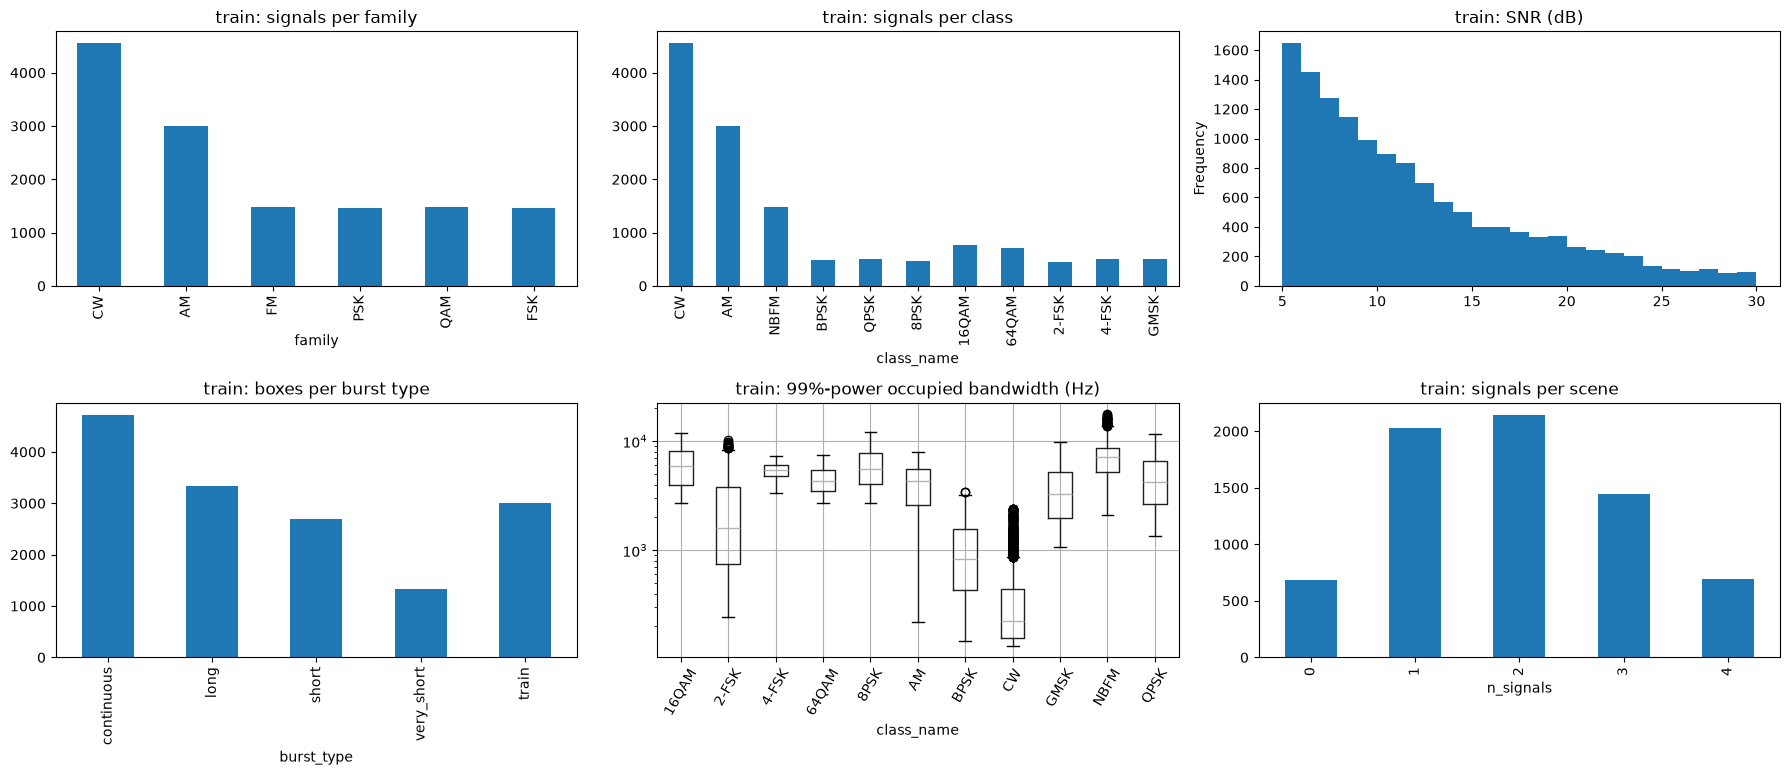

1 kHz set: scenes per spacing (Hz)  -> {250.0: 162, 500.0: 163, 750.0: 170, 1000.0: 791, 1500.0: 140, 2000.0: 156, 3000.0: 170, 5000.0: 163, 10000.0: 85}


tier measured from OBW,T1,T2,T3
tier by design,,,
T1,437,248,89
T2,84,371,174
T3,7,6,584


time overlap (ms),2.0,5.0,10.0,20.0,50.0,130.0
exactly 1 kHz: tier,,,,,,
T1,0,0,0,13,44,152
T2,0,22,55,63,36,64
T3,69,37,55,32,46,103


check: spacing between labeled centers vs design (max abs error, Hz): 1.4551915228366852e-11


In [16]:
frames = {n: read_tables(n) for n in SET_SIZES}
overview = pd.DataFrame([dict(set=n, scenes=len(sc), boxes=len(sg), empty_scenes=int((sc.n_signals == 0).sum()),
                              with_interferer=int((sc.n_interferers > 0).sum()), groups=sc.group_id.nunique()) for n, (sc, sg) in frames.items()])
display(overview)

sg_all = pd.concat([sg for _, sg in frames.values()])
tr = frames["train"][1]
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
tr.drop_duplicates(["scene_id", "sig_idx"]).family.value_counts().reindex(FAMILIES).plot.bar(ax=ax[0, 0], title="train: signals per family")
tr.drop_duplicates(["scene_id", "sig_idx"]).class_name.value_counts().reindex(KNOWN).plot.bar(ax=ax[0, 1], title="train: signals per class")
tr.drop_duplicates(["scene_id", "sig_idx"]).snr_db.plot.hist(bins=25, ax=ax[0, 2], title="train: SNR (dB)")
tr.burst_type.value_counts().reindex(list(CFG.burst_types) + ["overlap"]).dropna().plot.bar(ax=ax[1, 0], title="train: boxes per burst type")
tr.drop_duplicates(["scene_id", "sig_idx"]).boxplot(column="obw_hz", by="class_name", ax=ax[1, 1], rot=60)
ax[1, 1].set_title("train: 99%-power occupied bandwidth (Hz)"); ax[1, 1].set_yscale("log"); plt.sca(ax[1, 1]); plt.suptitle("")
frames["train"][0].n_signals.value_counts().sort_index().plot.bar(ax=ax[1, 2], title="train: signals per scene")
plt.tight_layout()
plt.show()

sc_p = frames["test_1khz"][0]
print("1 kHz set: scenes per spacing (Hz)  ->", sc_p.sep_hz.value_counts().sort_index().to_dict())
display(pd.crosstab(sc_p.tier_target, sc_p.tier_measured, rownames=["tier by design"], colnames=["tier measured from OBW"]))
display(pd.crosstab(sc_p[sc_p.sep_hz == 1000].tier_measured, sc_p[sc_p.sep_hz == 1000].overlap_ms, rownames=["exactly 1 kHz: tier"], colnames=["time overlap (ms)"]))
print("check: spacing between labeled centers vs design (max abs error, Hz):", float((sc_p.sep_measured_hz - sc_p.sep_hz).abs().max()))

## 13. Datasheet, loader and optional YOLO export

`DATASHEET.md` documents what the data contains and its known limitations. `SpectrumSet` reads a set with memory-mapped shards, ready for a PyTorch `DataLoader` (wrap `__getitem__`).

In [17]:
def build_datasheet():
    lines = [f"# Dataset datasheet: spectrum_rf v{CFG.version} ({PROFILE})", "",
             f"Generated {datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')} UTC with seed {CFG.base_seed}.", "",
             "## Format", f"- Spectrogram `[time={CFG.n_frames}, freq={CFG.n_fft}]`, uint8 dB relative to the noise floor: `db = q * {DB_STEP:.5f} + {CFG.db_min}`.",
             f"- fs = {CFG.fs:.0f} S/s complex, N_fft = {CFG.n_fft} ({DF:.0f} Hz bins), hop = {CFG.hop} ({CFG.hop / FS * 1e3:.2f} ms), Hann window, bins ascending from -fs/2.",
             f"- Scene = {NS} samples ({NS / FS * 1e3:.1f} ms). Raw IQ stored: {STORE_IQ}.", "",
             "## Sets", "| set | scenes | boxes | frozen |", "|---|---|---|---|"]
    for n, (sc, sg) in frames.items():
        lines.append(f"| {n} | {len(sc)} | {len(sg)} | {n in FROZEN_SETS} |")
    lines += ["", "## Labels (generated, not annotated)",
              "- Box frequency = the bounds holding 99% of the noise-free signal power (center +- OBW/2 for symmetric signals), minimum one bin (250 Hz).",
              "- Box time = frames whose window center lies inside the on-interval, minimum two frames. Each burst of a train is its own box.",
              "- Classes: " + ", ".join(KNOWN) + ". Families: " + ", ".join(FAMILIES) + ". Held out (test_openset only): " + ", ".join(UNKNOWN) + ".",
              "- SNR = in-band SNR over the occupied bandwidth (reference bandwidth at least 500 Hz), nominal (before fading).",
              f"- SNR sampling: `train` is skewed towards the 5 dB floor (truncated exponential, tau = {CFG.snr_tau_train} dB); `val` and all test sets are uniform in {CFG.snr_range[0]:.0f} to {CFG.snr_range[1]:.0f} dB.", "",
              "## Known limitations",
              "- Synthetic data: validate on real USRP captures before trusting absolute numbers (R&D Section 8).",
              "- Flat (narrowband) fading only; no multipath delay spread, no co-channel emitters outside the labeled signals.",
              "- Audio for AM/NBFM is synthetic (speech-like partials), not real speech.",
              "- Minimum symbol count per burst is enforced by raising the baud rate up to the class maximum; very short bursts of low-baud classes hold few symbols.",
              "- Box and mask are rectangles; overlapping signals share pixels and the mask keeps the last signal's family id.",
              "- PSK vs QAM are nearly indistinguishable in a magnitude spectrogram; use the coarse group or the stored IQ.",
              "- Signals with centers 1 kHz apart are separable in the spectrogram only when their bandwidths are small (tiers T1/T2); see `tier_measured`.",
              "- Spurs and impulses are present as unlabeled hard negatives (see `interferers_json`)."]
    (OUT_DIR / "DATASHEET.md").write_text("\n".join(lines) + "\n")


build_datasheet()


class SpectrumSet:
    # memory-mapped reader: set[i] -> dict(spec_db float32 [T,F], mask uint8 [T,F], iq complex64 or None, boxes DataFrame)
    def __init__(self, set_name, root=OUT_DIR):
        self.dir = Path(root) / "sets" / set_name
        self.scenes, self.signals = load_table(self.dir / "scenes"), load_table(self.dir / "signals")
        self.boxes = {k: g for k, g in self.signals.groupby("scene_id")}
        self._cache = {}

    def __len__(self):
        return len(self.scenes)

    def _shard(self, kind, k):
        key = (kind, k)
        if key not in self._cache:
            p = self.dir / f"shard_{k:04d}_{kind}"
            self._cache[key] = np.load(f"{p}.npz")["mask"] if kind == "mask" else np.load(f"{p}.npy", mmap_mode="r")
        return self._cache[key]

    def __getitem__(self, i):
        r = self.scenes.iloc[i]
        k, pos = int(r["shard"]), int(r["pos"])
        iq = None
        if (self.dir / f"shard_{k:04d}_iq.npy").exists():
            iq = iq_to_complex(np.asarray(self._shard("iq", k)[pos]), r["iq_scale"])
        return dict(spec_db=dequantize_db(np.asarray(self._shard("spec", k)[pos])), mask=np.asarray(self._shard("mask", k)[pos]), iq=iq,
                    boxes=self.boxes.get(r["scene_id"], self.signals.iloc[0:0]), scene=r)


ds = SpectrumSet("test_1khz")
item = ds[0]
print(len(ds), "scenes | spec", item["spec_db"].shape, "| mask classes", np.unique(item["mask"]), "| iq", None if item["iq"] is None else item["iq"].shape)
display(item["boxes"][["class_name", "family", "center_hz", "obw_hz", "snr_db", "burst_type", "box_x0", "box_x1", "box_y0", "box_y1"]])

2000 scenes | spec (128, 1024) | mask classes [0 4 6] | iq (33536,)


,class_name,family,center_hz,obw_hz,snr_db,burst_type,box_x0,box_x1,box_y0,box_y1
0,GMSK,FSK,-111801.32327,2417.96875,13.098391,overlap,60,69,121,122
1,QPSK,PSK,-112801.32327,2066.40625,21.980146,overlap,56,64,121,122


In [18]:
# Optional: export one set in YOLO format (PNG images + txt labels). Set EXPORT_YOLO=1 in the environment to enable.
EXPORT_YOLO = os.environ.get("EXPORT_YOLO", "0") == "1"


def export_yolo(set_name, limit=None):
    from PIL import Image
    ds_ = SpectrumSet(set_name)
    out = OUT_DIR / "yolo" / set_name
    (out / "images").mkdir(parents=True, exist_ok=True)
    (out / "labels").mkdir(parents=True, exist_ok=True)
    for i in tqdm(range(len(ds_) if limit is None else min(limit, len(ds_))), desc=f"yolo {set_name}"):
        it = ds_[i]
        img = np.clip((it["spec_db"] + 10) / 50 * 255, 0, 255).astype(np.uint8)          # -10..40 dB -> 0..255
        sid = it["scene"]["scene_id"]
        Image.fromarray(img).save(out / "images" / f"{sid}.png")
        W, H = CFG.n_fft, CFG.n_frames
        with open(out / "labels" / f"{sid}.txt", "w") as f:
            for b in it["boxes"].itertuples():
                if b.family_id > 6:
                    continue                                                           # held-out classes have no training label
                w, h = b.box_x1 - b.box_x0 + 1, b.box_y1 - b.box_y0 + 1
                f.write(f"{b.family_id - 1} {(b.box_x0 + w / 2) / W:.6f} {(b.box_y0 + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}\n")
    (out.parent / "dataset.yaml").write_text(f"path: {out.parent}\ntrain: train/images\nval: val/images\ntest: test/images\n"
                                             "names:\n" + "".join(f"  {i}: {f}\n" for i, f in enumerate(FAMILIES)))


if EXPORT_YOLO:
    for s in ("train", "val", "test"):
        export_yolo(s)
else:
    print("YOLO export skipped (set EXPORT_YOLO=1 to enable)")

YOLO export skipped (set EXPORT_YOLO=1 to enable)


In [19]:
EXPORT_YOLO

False

## 14. What is in the output folder and next steps

```
dataset/spectrum_rf_v<version>_<profile>/
  config.json, DATASHEET.md, qa_overlays_train.png
  sets/<set>/ shard_XXXX_{spec,iq}.npy  shard_XXXX_mask.npz  scenes.*  signals.*  coco.json  _SUCCESS
```

Next steps (R&D Sections 4 to 7):

1. Train the baselines on `train` / `val` and report on the frozen sets: CFAR and a spectrogram CNN / YOLO for detection, a ResNet for family classification.
2. Evaluate the 1 kHz success criterion on `test_1khz` per tier, SNR, spacing and time overlap.
3. Capture real data with the USRP (cabled test signals, 1 kHz pairs) and measure the sim-to-real gap.
4. Scale with `SPECTRUM_PROFILE=main` once the labels and the receiver model look right.

## 15. Ten random spectrograms from the dataset, explained

This section draws **10 random scenes** from a stored set (default `train`, scenes with at least one labeled signal) and explains every feature visible in them. Set `SPECTRUM_SHOW_SEED` for another draw, or `SPECTRUM_SHOW_SET` to look at another set (for example `test_1khz` or `test_openset`).

**How to read one spectrogram**

| Element | Meaning |
|---|---|
| Horizontal axis | frequency, -128 to +128 kHz around the receiver center (1024 bins of 250 Hz) |
| Vertical axis | time, 0 to about 131 ms (128 frames, 1 ms apart), time runs downward |
| Color | power in dB **relative to the noise floor** (0 dB = pure noise); dark = noise only, bright = signal |
| Colored rectangle | the automatic label of one signal burst: frequency bounds holding 99% of the signal power x the frames in which it is on |
| Box color | modulation family: white CW, yellow AM, cyan FM, lime PSK, magenta QAM, orange FSK, red unknown (open-set only) |
| Text on a box | fine class and nominal in-band SNR |

**Receiver effects to look for:** a thin bright line at 0 kHz (DC offset), a darker fall-off towards both band edges (anti-alias filter roll-off), thin unlabeled lines (spurs) and short vertical stripes (impulses) that act as hard negatives, and signals shifted by a few hundred Hz (oscillator error in ppm).

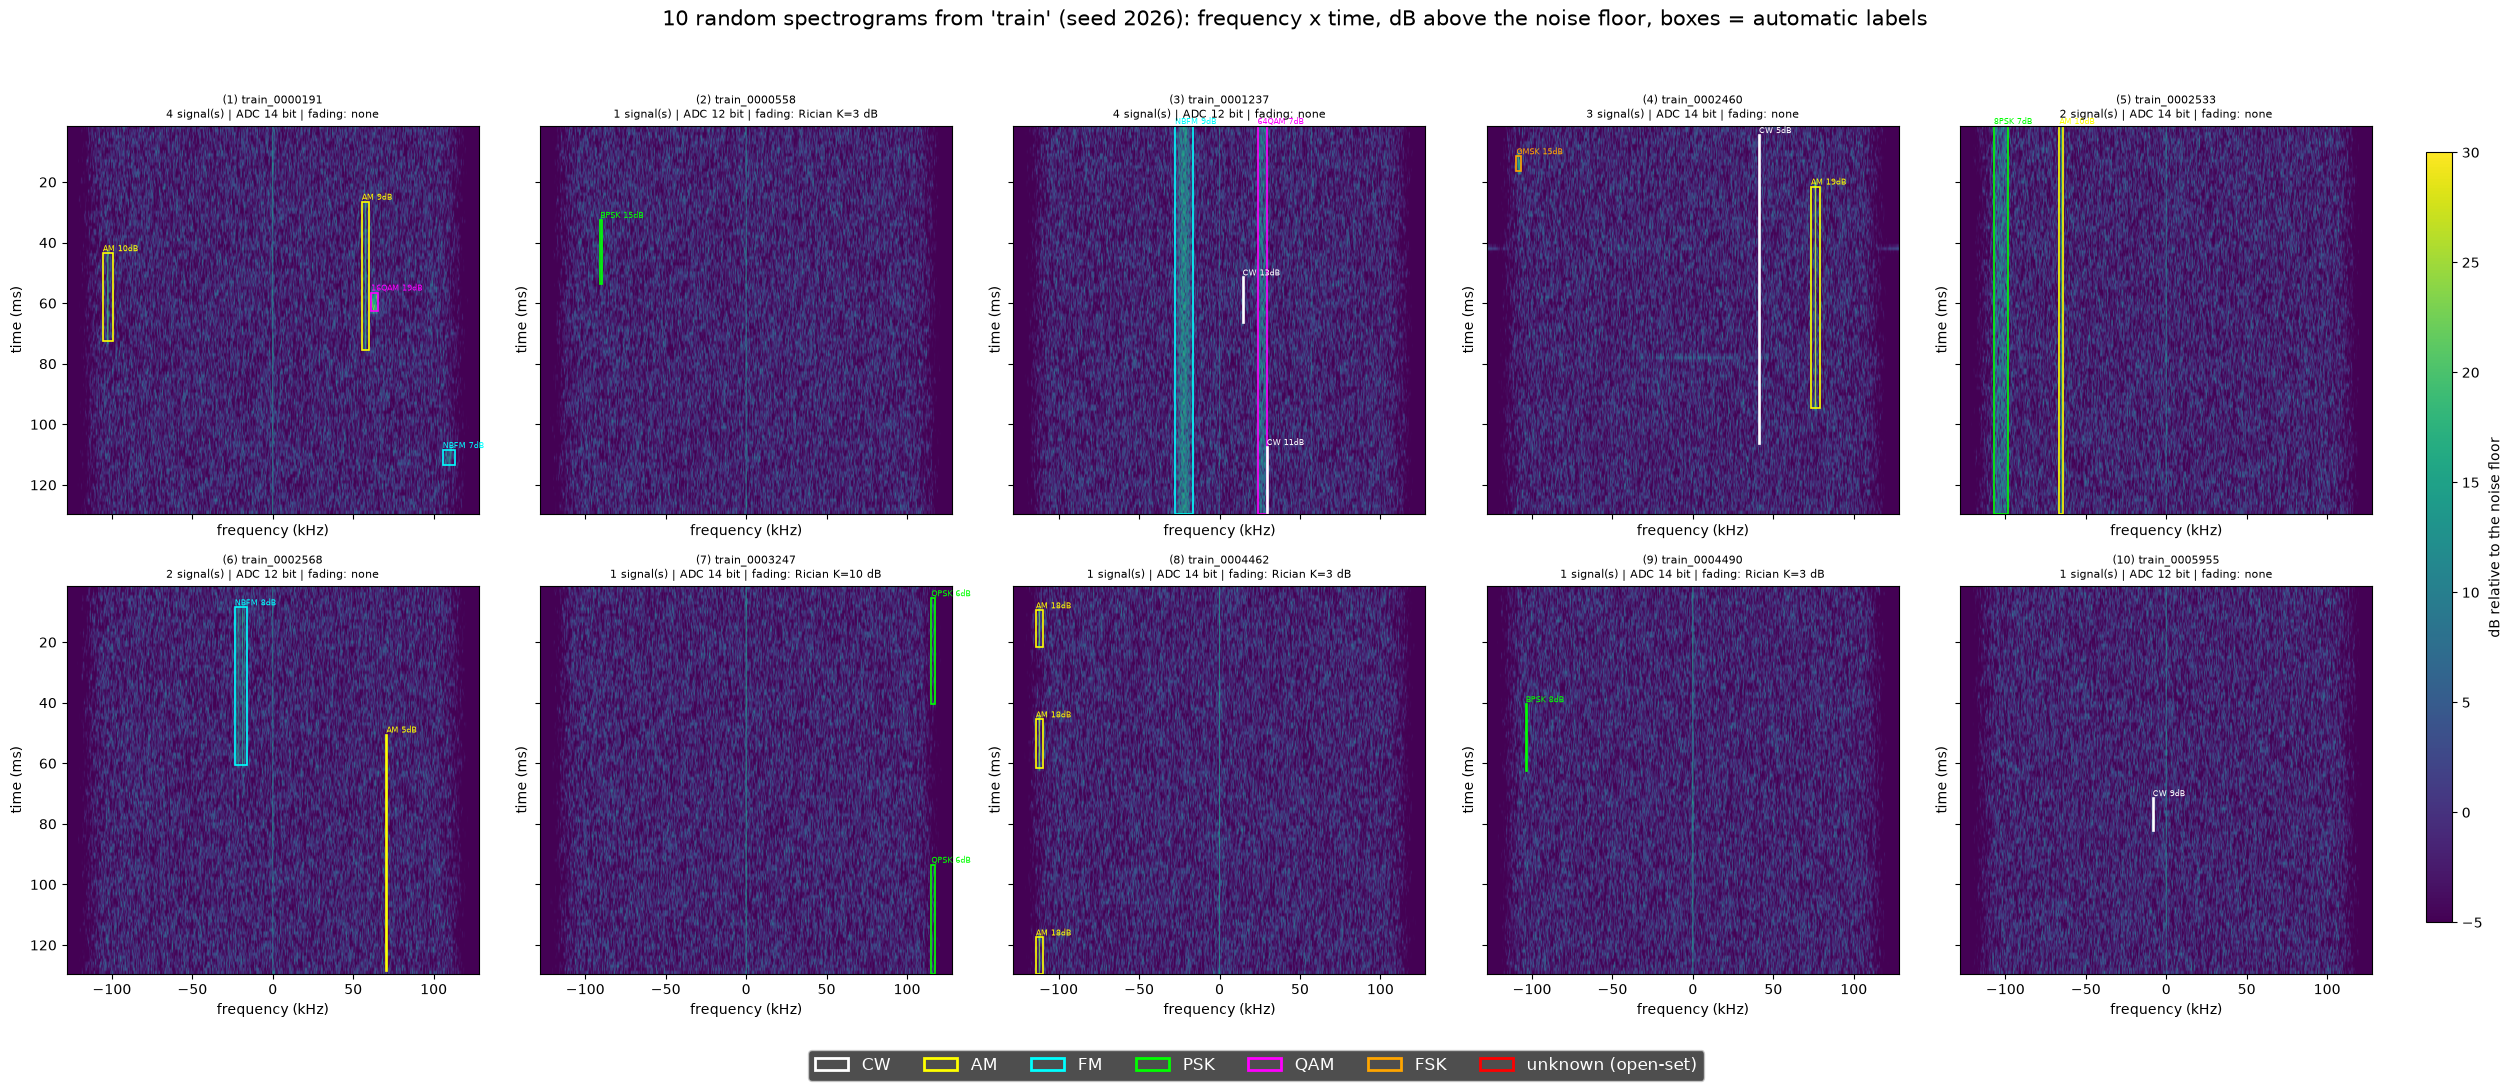

In [20]:
from matplotlib.patches import Patch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from IPython.display import Markdown, display

SHOW_SET = os.environ.get("SPECTRUM_SHOW_SET", "train")
SHOW_SEED = int(os.environ.get("SPECTRUM_SHOW_SEED", "2026"))      # change for another random draw
N_SHOW = 10
FADING_TXT = {0: "none (static channel)", 1: "Rician K=10 dB (mild fading)", 2: "Rician K=3 dB (strong fading)", 3: "Rayleigh (no line of sight)"}

show_ds = SpectrumSet(SHOW_SET)
candidates = np.flatnonzero(show_ds.scenes["n_boxes"].to_numpy() > 0)      # skip noise-only scenes
show_idx = np.sort(np.random.default_rng(SHOW_SEED).choice(candidates, N_SHOW, replace=False))

fig, axes = plt.subplots(2, 5, figsize=(26, 11), sharex=True, sharey=True)
for k, (ax, i) in enumerate(zip(axes.ravel(), show_idx), 1):
    r = show_ds.scenes.iloc[int(i)]
    plot_scene(stored_scene(SHOW_SET, r, show_ds.signals), ax=ax,
               title=f'({k}) {r["scene_id"]}\n{int(r["n_signals"])} signal(s) | ADC {int(r["adc_bits"])} bit | fading: {FADING_TXT[int(r["fading_level"])].split(" (")[0]}')
fig.suptitle(f"{N_SHOW} random spectrograms from '{SHOW_SET}' (seed {SHOW_SEED}): frequency x time, dB above the noise floor, boxes = automatic labels", fontsize=15)
fig.tight_layout(rect=[0, 0.05, 0.92, 0.95])
cax = fig.add_axes([0.935, 0.15, 0.01, 0.7])
fig.colorbar(ScalarMappable(norm=Normalize(-5, 30), cmap="viridis"), cax=cax, label="dB relative to the noise floor")
handles = [Patch(fill=False, ec=FAM_COLORS[FAMILY_ID[f]], lw=2, label=f) for f in FAMILIES] + [Patch(fill=False, ec=FAM_COLORS[7], lw=2, label="unknown (open-set)")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), facecolor="#222222", labelcolor="white", fontsize=12)
fig.savefig(OUT_DIR / "section15_random_spectrograms.png", dpi=130)
plt.show()

In [21]:
WHAT_YOU_SEE = {
    "CW": "one razor-thin vertical line (1 to 2 bins, about 250 to 500 Hz): an unmodulated carrier. Only the burst envelope (on/off keying) changes it in time.",
    "AM": "a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.",
    "NBFM": "a band of roughly 2 x (deviation + audio bandwidth), about 6 to 12 kHz wide, with a bright core and edges that wander with the audio; constant envelope, so the energy is smooth in time.",
    "BPSK": "a smooth flat-topped block with steep (root-raised-cosine) edges, about baud x (1 + roll-off) wide, constant energy over the burst.",
    "QPSK": "same look as BPSK: a flat-topped block about baud x (1 + roll-off) wide; the phase states are invisible in a magnitude spectrogram.",
    "8PSK": "a flat-topped block about baud x (1 + roll-off) wide; indistinguishable from QPSK or QAM by eye.",
    "16QAM": "a flat-topped block about baud x (1 + roll-off) wide; PSK and QAM differ only in amplitude states, so the family needs the coarse group or the raw IQ.",
    "64QAM": "a flat-topped block about baud x (1 + roll-off) wide, with slightly more energy texture from the many amplitude states.",
    "2-FSK": "two preferred frequencies, about mod_index x baud apart; with the Gaussian smoothing they appear as a twin-peaked, wider-than-PSK shape with energy shifting between the peaks over time.",
    "4-FSK": "four frequency positions, giving a wider multi-peaked band whose energy hops between several levels over time.",
    "GMSK": "a compact, smooth, bell-shaped band about one baud wide with constant envelope: narrower and softer-edged than a linear modulation of the same rate.",
    "OQPSK": "(held out) looks like QPSK but with different envelope behavior; designed to test whether the model rejects unseen classes.",
    "8-FSK": "(held out) an FSK-like multi-peaked band with eight frequency positions.",
    "CHIRP": "(held out) a diagonal streak: the frequency sweeps linearly with time.",
}
BURST_TXT = {"continuous": "continuous (on the whole scene)", "long": "long burst", "short": "short burst", "very_short": "very short burst (stress case)", "train": "burst train (repeated on/off keying)"}


def fmt_params(p):
    d = json.loads(p) if isinstance(p, str) else {}
    return ", ".join(f"{k}={v:.4g}" if isinstance(v, (int, float)) else f"{k}={v}" for k, v in d.items()) or "none"


def fmt_interferers(s):
    out = []
    for d in (json.loads(s) if isinstance(s, str) else []):
        if d.get("kind") == "spur":
            out.append(f"spur at {d['center_hz'] / 1e3:+.1f} kHz ({d['snr_db']:.1f} dB, a thin unlabeled line)")
        else:
            out.append(f"{d.get('kind', 'interferer')} (a short unlabeled vertical stripe)")
    return ", ".join(out) or "none"


summary = []
for k, i in enumerate(show_idx, 1):
    r = show_ds.scenes.iloc[int(i)]
    sg = show_ds.boxes.get(r["scene_id"], show_ds.signals.iloc[0:0])
    db = dequantize_db(stored_scene(SHOW_SET, r, show_ds.signals)["spec"])
    floor = float(np.median(db))
    lines = [f"### ({k}) `{r['scene_id']}`",
             f"**Receiver and session:** RF carrier {r['rf_hz'] / 1e6:.3f} MHz, oscillator error {r['ppm']:g} ppm (common frequency shift {r['cfo_hz']:+.0f} Hz), "
             f"ADC {int(r['adc_bits'])} bit, IQ image rejection {r['irr_db']:.1f} dB, DC offset {r['dc_rel']:.3f} (relative), fading: {FADING_TXT[int(r['fading_level'])]}.",
             f"**Scene:** mode `{r['mode']}`, {int(r['n_signals'])} labeled signal(s) in {len(sg)} box(es); noise floor of the image (median) = {floor:+.1f} dB; "
             f"unlabeled hard negatives: {fmt_interferers(r['interferers_json'])}.",
             "**Labeled signals:**"]
    for b in sg.itertuples():
        reg = db[b.box_y0:b.box_y1 + 1, b.box_x0:b.box_x1 + 1]
        burst = f" (burst {int(b.burst_idx) + 1})" if b.burst_type == "train" else ""
        lines.append(
            f"- **{b.class_name}**{burst}: family `{b.family}`, coarse group `{b.coarse}`; center {b.center_hz / 1e3:+.2f} kHz, occupied bandwidth {b.obw_hz / 1e3:.2f} kHz "
            f"(box {b.box_x1 - b.box_x0 + 1} bins x {b.box_y1 - b.box_y0 + 1} frames); {BURST_TXT[b.burst_type]}, on from {b.t_start_s * 1e3:.1f} to {b.t_end_s * 1e3:.1f} ms "
            f"({(b.t_end_s - b.t_start_s) * 1e3:.1f} ms); nominal SNR {b.snr_db:.1f} dB, measured mean level inside the box {reg.mean():+.1f} dB; parameters: {fmt_params(b.params_json)}.  \n"
            f"  *What to look for:* {WHAT_YOU_SEE.get(b.class_name, '')}")
    display(Markdown("\n".join(lines)))
    summary.append(dict(n=k, scene=r["scene_id"], signals=", ".join(sg.class_name), rf_MHz=round(r["rf_hz"] / 1e6, 3), ppm=r["ppm"], adc_bits=int(r["adc_bits"]),
                        fading=int(r["fading_level"]), irr_db=round(r["irr_db"], 1), interferers=int(r["n_interferers"]), floor_db=round(floor, 1)))
pd.DataFrame(summary).set_index("n")

### (1) `train_0000191`
**Receiver and session:** RF carrier 156.800 MHz, oscillator error 2 ppm (common frequency shift -131 Hz), ADC 14 bit, IQ image rejection 32.7 dB, DC offset 0.167 (relative), fading: none (static channel).
**Scene:** mode `general`, 4 labeled signal(s) in 4 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **16QAM**: family `QAM`, coarse group `LinearDigital`; center +63.26 kHz, occupied bandwidth 4.01 kHz (box 17 bins x 6 frames); very short burst (stress case), on from 56.7 to 62.7 ms (6.0 ms); nominal SNR 18.7 dB, measured mean level inside the box +15.2 dB; parameters: baud=3282, rolloff=0.4899.  
  *What to look for:* a flat-topped block about baud x (1 + roll-off) wide; PSK and QAM differ only in amplitude states, so the family needs the coarse group or the raw IQ.
- **NBFM**: family `FM`, coarse group `Analog`; center +109.50 kHz, occupied bandwidth 7.57 kHz (box 31 bins x 5 frames); very short burst (stress case), on from 108.4 to 113.8 ms (5.4 ms); nominal SNR 7.1 dB, measured mean level inside the box +1.8 dB; parameters: deviation_hz=5000, audio_bw_hz=2557.  
  *What to look for:* a band of roughly 2 x (deviation + audio bandwidth), about 6 to 12 kHz wide, with a bright core and edges that wander with the audio; constant envelope, so the energy is smooth in time.
- **AM**: family `AM`, coarse group `Analog`; center -102.47 kHz, occupied bandwidth 6.27 kHz (box 26 bins x 29 frames); short burst, on from 43.5 to 73.0 ms (29.5 ms); nominal SNR 9.8 dB, measured mean level inside the box +1.0 dB; parameters: audio_bw_hz=3605, mod_index=0.6177.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.
- **AM**: family `AM`, coarse group `Analog`; center +57.64 kHz, occupied bandwidth 4.26 kHz (box 18 bins x 49 frames); long burst, on from 26.7 to 75.0 ms (48.3 ms); nominal SNR 8.7 dB, measured mean level inside the box +2.6 dB; parameters: audio_bw_hz=3039, mod_index=0.7651.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.

### (2) `train_0000558`
**Receiver and session:** RF carrier 435.000 MHz, oscillator error 0.1 ppm (common frequency shift -16 Hz), ADC 12 bit, IQ image rejection 46.1 dB, DC offset 0.153 (relative), fading: Rician K=3 dB (strong fading).
**Scene:** mode `general`, 1 labeled signal(s) in 1 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **BPSK**: family `PSK`, coarse group `LinearDigital`; center -89.91 kHz, occupied bandwidth 0.98 kHz (box 5 bins x 21 frames); short burst, on from 32.1 to 53.8 ms (21.7 ms); nominal SNR 15.3 dB, measured mean level inside the box +8.0 dB; parameters: baud=807.6, rolloff=0.2849.  
  *What to look for:* a smooth flat-topped block with steep (root-raised-cosine) edges, about baud x (1 + roll-off) wide, constant energy over the burst.

### (3) `train_0001237`
**Receiver and session:** RF carrier 446.100 MHz, oscillator error 2 ppm (common frequency shift +80 Hz), ADC 12 bit, IQ image rejection 42.7 dB, DC offset 0.085 (relative), fading: none (static channel).
**Scene:** mode `general`, 4 labeled signal(s) in 4 box(es); noise floor of the image (median) = -2.1 dB; unlabeled hard negatives: spur at +57.1 kHz (2.8 dB, a thin unlabeled line).
**Labeled signals:**
- **CW**: family `CW`, coarse group `Carrier`; center +14.73 kHz, occupied bandwidth 0.53 kHz (box 3 bins x 15 frames); short burst, on from 51.4 to 66.7 ms (15.3 ms); nominal SNR 12.7 dB, measured mean level inside the box +9.6 dB; parameters: none.  
  *What to look for:* one razor-thin vertical line (1 to 2 bins, about 250 to 500 Hz): an unmodulated carrier. Only the burst envelope (on/off keying) changes it in time.
- **64QAM**: family `QAM`, coarse group `LinearDigital`; center +26.53 kHz, occupied bandwidth 5.77 kHz (box 24 bins x 128 frames); continuous (on the whole scene), on from 0.0 to 131.0 ms (131.0 ms); nominal SNR 6.8 dB, measured mean level inside the box +5.0 dB; parameters: baud=5224, rolloff=0.2025.  
  *What to look for:* a flat-topped block about baud x (1 + roll-off) wide, with slightly more energy texture from the many amplitude states.
- **NBFM**: family `FM`, coarse group `Analog`; center -22.11 kHz, occupied bandwidth 10.88 kHz (box 44 bins x 128 frames); continuous (on the whole scene), on from 0.0 to 131.0 ms (131.0 ms); nominal SNR 8.8 dB, measured mean level inside the box +5.9 dB; parameters: deviation_hz=5000, audio_bw_hz=2545.  
  *What to look for:* a band of roughly 2 x (deviation + audio bandwidth), about 6 to 12 kHz wide, with a bright core and edges that wander with the audio; constant envelope, so the energy is smooth in time.
- **CW**: family `CW`, coarse group `Carrier`; center +29.81 kHz, occupied bandwidth 0.58 kHz (box 3 bins x 22 frames); short burst, on from 107.9 to 131.0 ms (23.1 ms); nominal SNR 10.7 dB, measured mean level inside the box +9.2 dB; parameters: none.  
  *What to look for:* one razor-thin vertical line (1 to 2 bins, about 250 to 500 Hz): an unmodulated carrier. Only the burst envelope (on/off keying) changes it in time.

### (4) `train_0002460`
**Receiver and session:** RF carrier 435.000 MHz, oscillator error 2 ppm (common frequency shift -126 Hz), ADC 14 bit, IQ image rejection 42.0 dB, DC offset 0.009 (relative), fading: none (static channel).
**Scene:** mode `general`, 3 labeled signal(s) in 3 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: impulse (a short unlabeled vertical stripe).
**Labeled signals:**
- **GMSK**: family `FSK`, coarse group `FSKDigital`; center -108.13 kHz, occupied bandwidth 2.57 kHz (box 12 bins x 5 frames); very short burst (stress case), on from 11.0 to 16.9 ms (5.9 ms); nominal SNR 15.0 dB, measured mean level inside the box +8.2 dB; parameters: baud=2723, mod_index=0.5, gauss_bt=0.3, M=2.  
  *What to look for:* a compact, smooth, bell-shaped band about one baud wide with constant envelope: narrower and softer-edged than a linear modulation of the same rate.
- **CW**: family `CW`, coarse group `Carrier`; center +41.48 kHz, occupied bandwidth 0.15 kHz (box 2 bins x 102 frames); long burst, on from 4.7 to 106.1 ms (101.4 ms); nominal SNR 5.1 dB, measured mean level inside the box +3.6 dB; parameters: none.  
  *What to look for:* one razor-thin vertical line (1 to 2 bins, about 250 to 500 Hz): an unmodulated carrier. Only the burst envelope (on/off keying) changes it in time.
- **AM**: family `AM`, coarse group `Analog`; center +76.17 kHz, occupied bandwidth 5.30 kHz (box 22 bins x 73 frames); long burst, on from 21.2 to 94.0 ms (72.9 ms); nominal SNR 18.5 dB, measured mean level inside the box +3.2 dB; parameters: audio_bw_hz=3081, mod_index=0.4193.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.

### (5) `train_0002533`
**Receiver and session:** RF carrier 121.500 MHz, oscillator error 2 ppm (common frequency shift +27 Hz), ADC 14 bit, IQ image rejection 45.7 dB, DC offset 0.122 (relative), fading: none (static channel).
**Scene:** mode `general`, 2 labeled signal(s) in 2 box(es); noise floor of the image (median) = -2.1 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **8PSK**: family `PSK`, coarse group `LinearDigital`; center -102.77 kHz, occupied bandwidth 8.69 kHz (box 35 bins x 128 frames); continuous (on the whole scene), on from 0.0 to 131.0 ms (131.0 ms); nominal SNR 7.1 dB, measured mean level inside the box +5.2 dB; parameters: baud=7758, rolloff=0.2376.  
  *What to look for:* a flat-topped block about baud x (1 + roll-off) wide; indistinguishable from QPSK or QAM by eye.
- **AM**: family `AM`, coarse group `Analog`; center -65.20 kHz, occupied bandwidth 2.27 kHz (box 10 bins x 128 frames); continuous (on the whole scene), on from 0.0 to 131.0 ms (131.0 ms); nominal SNR 9.9 dB, measured mean level inside the box +2.9 dB; parameters: audio_bw_hz=3775, mod_index=0.6071.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.

### (6) `train_0002568`
**Receiver and session:** RF carrier 435.000 MHz, oscillator error 2 ppm (common frequency shift +661 Hz), ADC 12 bit, IQ image rejection 40.8 dB, DC offset 0.128 (relative), fading: none (static channel).
**Scene:** mode `general`, 2 labeled signal(s) in 2 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **NBFM**: family `FM`, coarse group `Analog`; center -19.90 kHz, occupied bandwidth 7.24 kHz (box 30 bins x 52 frames); long burst, on from 8.7 to 60.8 ms (52.1 ms); nominal SNR 8.0 dB, measured mean level inside the box +3.5 dB; parameters: deviation_hz=2500, audio_bw_hz=2862.  
  *What to look for:* a band of roughly 2 x (deviation + audio bandwidth), about 6 to 12 kHz wide, with a bright core and edges that wander with the audio; constant envelope, so the energy is smooth in time.
- **AM**: family `AM`, coarse group `Analog`; center +70.86 kHz, occupied bandwidth 0.27 kHz (box 2 bins x 78 frames); long burst, on from 50.6 to 128.2 ms (77.5 ms); nominal SNR 5.1 dB, measured mean level inside the box +4.3 dB; parameters: audio_bw_hz=3226, mod_index=0.3136.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.

### (7) `train_0003247`
**Receiver and session:** RF carrier 446.100 MHz, oscillator error 2 ppm (common frequency shift +195 Hz), ADC 14 bit, IQ image rejection 39.1 dB, DC offset 0.197 (relative), fading: Rician K=10 dB (mild fading).
**Scene:** mode `general`, 1 labeled signal(s) in 2 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **QPSK** (burst 1): family `PSK`, coarse group `LinearDigital`; center +116.38 kHz, occupied bandwidth 2.42 kHz (box 10 bins x 35 frames); burst train (repeated on/off keying), on from 5.3 to 40.9 ms (35.6 ms); nominal SNR 5.7 dB, measured mean level inside the box -1.7 dB; parameters: baud=2169, rolloff=0.2296.  
  *What to look for:* same look as BPSK: a flat-topped block about baud x (1 + roll-off) wide; the phase states are invisible in a magnitude spectrogram.
- **QPSK** (burst 2): family `PSK`, coarse group `LinearDigital`; center +116.38 kHz, occupied bandwidth 2.42 kHz (box 10 bins x 36 frames); burst train (repeated on/off keying), on from 93.1 to 131.0 ms (37.9 ms); nominal SNR 5.7 dB, measured mean level inside the box -2.4 dB; parameters: baud=2169, rolloff=0.2296.  
  *What to look for:* same look as BPSK: a flat-topped block about baud x (1 + roll-off) wide; the phase states are invisible in a magnitude spectrogram.

### (8) `train_0004462`
**Receiver and session:** RF carrier 446.100 MHz, oscillator error 0.1 ppm (common frequency shift -10 Hz), ADC 14 bit, IQ image rejection 49.3 dB, DC offset 0.194 (relative), fading: Rician K=3 dB (strong fading).
**Scene:** mode `general`, 1 labeled signal(s) in 3 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **AM** (burst 1): family `AM`, coarse group `Analog`; center -111.98 kHz, occupied bandwidth 4.14 kHz (box 17 bins x 12 frames); burst train (repeated on/off keying), on from 9.8 to 21.0 ms (11.2 ms); nominal SNR 18.3 dB, measured mean level inside the box +2.1 dB; parameters: audio_bw_hz=3914, mod_index=0.4859.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.
- **AM** (burst 2): family `AM`, coarse group `Analog`; center -111.98 kHz, occupied bandwidth 4.14 kHz (box 17 bins x 16 frames); burst train (repeated on/off keying), on from 45.3 to 61.4 ms (16.1 ms); nominal SNR 18.3 dB, measured mean level inside the box +1.7 dB; parameters: audio_bw_hz=3914, mod_index=0.4859.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.
- **AM** (burst 3): family `AM`, coarse group `Analog`; center -111.98 kHz, occupied bandwidth 4.14 kHz (box 17 bins x 12 frames); burst train (repeated on/off keying), on from 117.8 to 131.0 ms (13.2 ms); nominal SNR 18.3 dB, measured mean level inside the box +1.7 dB; parameters: audio_bw_hz=3914, mod_index=0.4859.  
  *What to look for:* a bright carrier line with weaker sidebands on both sides; the sideband width equals the audio bandwidth and its brightness flickers with the syllables of the speech-like audio.

### (9) `train_0004490`
**Receiver and session:** RF carrier 446.100 MHz, oscillator error 0.1 ppm (common frequency shift -12 Hz), ADC 14 bit, IQ image rejection 49.3 dB, DC offset 0.194 (relative), fading: Rician K=3 dB (strong fading).
**Scene:** mode `general`, 1 labeled signal(s) in 1 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **BPSK**: family `PSK`, coarse group `LinearDigital`; center -103.58 kHz, occupied bandwidth 0.54 kHz (box 3 bins x 22 frames); short burst, on from 40.8 to 62.1 ms (21.2 ms); nominal SNR 8.3 dB, measured mean level inside the box +4.7 dB; parameters: baud=377, rolloff=0.4382.  
  *What to look for:* a smooth flat-topped block with steep (root-raised-cosine) edges, about baud x (1 + roll-off) wide, constant energy over the burst.

### (10) `train_0005955`
**Receiver and session:** RF carrier 145.500 MHz, oscillator error 2 ppm (common frequency shift -222 Hz), ADC 12 bit, IQ image rejection 33.7 dB, DC offset 0.142 (relative), fading: none (static channel).
**Scene:** mode `general`, 1 labeled signal(s) in 1 box(es); noise floor of the image (median) = -2.4 dB; unlabeled hard negatives: none.
**Labeled signals:**
- **CW**: family `CW`, coarse group `Carrier`; center -8.01 kHz, occupied bandwidth 0.62 kHz (box 3 bins x 11 frames); short burst, on from 71.3 to 82.4 ms (11.1 ms); nominal SNR 8.9 dB, measured mean level inside the box +7.6 dB; parameters: none.  
  *What to look for:* one razor-thin vertical line (1 to 2 bins, about 250 to 500 Hz): an unmodulated carrier. Only the burst envelope (on/off keying) changes it in time.

,scene,signals,rf_MHz,ppm,adc_bits,fading,irr_db,interferers,floor_db
n,,,,,,,,,
1,train_0000191,"16QAM, NBFM, AM, AM",156.8,2.0,14,0,32.7,0,-2.4
2,train_0000558,BPSK,435.0,0.1,12,2,46.1,0,-2.4
3,train_0001237,"CW, 64QAM, NBFM, CW",446.1,2.0,12,0,42.7,1,-2.1
4,train_0002460,"GMSK, CW, AM",435.0,2.0,14,0,42.0,1,-2.4
5,train_0002533,"8PSK, AM",121.5,2.0,14,0,45.7,0,-2.1
6,train_0002568,"NBFM, AM",435.0,2.0,12,0,40.8,0,-2.4
7,train_0003247,"QPSK, QPSK",446.1,2.0,14,1,39.1,0,-2.4
8,train_0004462,"AM, AM, AM",446.1,0.1,14,2,49.3,0,-2.4
9,train_0004490,BPSK,446.1,0.1,14,2,49.3,0,-2.4


**Talking points for the presentation**

1. Every image is one 131 ms capture of a 256 kHz-wide band; the model sees a 128 x 1024 picture and must find *where* (box) and *what* (family) each signal is.
2. Signals differ in **shape**: lines (CW), line plus sidebands (AM), narrow wavering bands (NBFM), flat blocks (PSK/QAM), multi-peaked bands (FSK), compact bell shapes (GMSK).
3. Signals differ in **time behavior**: continuous, long, short and very short bursts, and trains. Each burst is its own box.
4. **SNR decides visibility**: boxes at 5 dB are barely above the noise, boxes at 30 dB are bright; the generator knows the exact value because the signal is synthetic.
5. **Receiver and session effects** (ADC bits, fading, ppm shift, IQ imbalance, DC line, band-edge roll-off) change the look of otherwise identical signals, so a model has to be robust to them.
6. **Hard negatives** (spurs and impulses) are bright but unlabeled, so a detector must learn not to fire on them.
7. PSK and QAM look almost the same in magnitude; this is why the dataset also stores a coarse group and the raw IQ.
8. All labels come from the generator, so they are exact and free, but real USRP captures are still needed to measure the sim-to-real gap.